# SEER: clinically constrained conditional VAE

Experimental companion to `breast_cancer.ipynb`. Learn the **13 original predictors**
conditional on five-year outcome; do not rebuild the existing baseline classifier.
Synthetic patients are research inputs, not independent clinical evidence.

**Windows 11 CPU / Colab T4:** identical float32 implementation, automatic GPU detection,
no CUDA toolkit required for CPU, no BF16/AMP, no multiprocessing. A GPU is optional for
this small network. Exact reproducibility across hardware is not guaranteed.

**Execution status:** delivered without running training, at the user's request.
The final cells calculate evidence-based feasibility and write outputs when you run them.
Passing implemented constraints does not establish complete clinical validity or fairness.

**Revision:** mild regularization (encoder/decoder dropout 0.10, weight decay 5e-4),
logged epoch progress, joint empirical staging distribution, and checkpoint evaluation recovery.
No new training results are claimed. Previous outputs are preserved in `seer_cvae_previous_run.ipynb`.


Run the notebook from the top after editing **Configuration and hyperparameters**.
Saved outputs are from the last executed run and are retained for reference.
The final learning-rate comparison is optional and reuses the same data and scoring functions.


## 1. Configuration and reproducibility

Windows, Python 3.11+ recommended, from this project folder:
```powershell
py -3.11 -m venv .venv
.\.venv\Scripts\python.exe -m pip install torch --index-url https://download.pytorch.org/whl/cpu
.\.venv\Scripts\python.exe -m pip install -r requirements.txt
.\.venv\Scripts\python.exe -m jupyter lab seer_cvae_synthetic_generation.ipynb
```
Colab: select **Runtime → Change runtime type → T4 GPU**, then upload this notebook and
the CSV. The setup cell installs missing packages without replacing an existing CUDA torch.
Do not run the Windows CPU installation command in Colab. Optional Drive input/output is
configurable below. Download the output ZIP or use a mounted Drive path to retain results.

Default experiments vary seed, latent width, beta, class weighting and maximum duration.
`RUN_PROFILE="smoke"` performs a short execution check, not a scientific assessment.

**After installing dependencies, restart the kernel** before Run All. An early pandas
self-check detects a stale mixed-version kernel. To evaluate the existing run without
training, set `RESUME_FROM=Path("cvae_output/20261110_192128")` in configuration and
run top-to-bottom. Exact original split IDs/scaling/categories are checked; models retain
their original regularization and independent staging heads. New outputs go to a separate
evaluation folder. Leave `RESUME_FROM=None` to train the revised model instead.


### Imports and dependency checks

In [1]:
import importlib.util
import importlib.metadata
import os
import sys
import subprocess
try:
    IN_COLAB = importlib.util.find_spec("google.colab") is not None
except ModuleNotFoundError:
    IN_COLAB = False
PACKAGES = {"numpy": "numpy", "pandas": "pandas", "scipy": "scipy", "sklearn": "scikit-learn",
            "matplotlib": "matplotlib", "seaborn": "seaborn", "joblib": "joblib", "torch": "torch"}
missing = [p for m, p in PACKAGES.items() if importlib.util.find_spec(m) is None]
if missing:
    if IN_COLAB:
        subprocess.check_call([sys.executable, "-m", "pip", "install", *missing])
    else:
        raise ImportError(f"Missing {missing}; follow the Windows setup above using this kernel's Python.")
# Fail before loading data/training if pip changed pandas beneath this kernel.
if "pandas" in sys.modules:
    installed = importlib.metadata.version("pandas")
    loaded = sys.modules["pandas"].__version__
    if installed != loaded:
        raise RuntimeError(f"Pandas loaded={loaded}, installed={installed}. Restart the Jupyter kernel after pip installs.")
os.environ.setdefault("CUBLAS_WORKSPACE_CONFIG", ":4096:8")
from pathlib import Path
import copy
import hashlib
import json
import math
import platform
import random
import shutil
import time
import warnings
import joblib
import numpy as np
import pandas as pd
import torch
from torch import nn
from torch.nn import functional as F
from torch.utils.data import DataLoader, TensorDataset
from scipy import stats
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.decomposition import PCA
from sklearn.base import clone
from sklearn.metrics import (pairwise_distances, average_precision_score, roc_auc_score,
                             brier_score_loss, balanced_accuracy_score, confusion_matrix)
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown


### Configuration and hyperparameters

Edit this cell to choose the split, model, search and evaluation settings.

In [2]:
PROJECT_DIR = Path(r"C:\Users\Tommaso\Code\progetto")
CSV_NAME = "Copia di SEER Breast Cancer Dataset .csv"
DATA_PATH = None
MOUNT_DRIVE = False
DRIVE_PROJECT = Path("/content/drive/MyDrive/progettoneuro")
OUTPUT_ROOT = Path("cvae_output")  # May point to mounted Google Drive.
SPLIT_PATH = None  # JSON schema in section 3; exact baseline manifest if available.
RESUME_FROM = Path("cvae_output/20261111_121445_regularized")
# Search and generation
AUTO_TUNE = True
SEARCH_TRIALS = 12
BETA_RANGE = (.06, .16)
DROPOUT_RANGE = (.05, .16)
LR_RANGE = (.0005, .003)
SEARCH_SEEDS = (42, 123)
GENERATION_SEEDS = (701, 702, 703)
WARM_START_RUN = None  # None uses the discrete-age checkpoint from this same training split.
RUN_PROFILE = "standard"  # standard / smoke
DEVICE_OVERRIDE = "auto"  # auto / cpu / cuda
# Data split
SEED = 42
TEST_FRACTION = 0.20
VALIDATION_FRACTION = 0.20  # Fraction of the remaining development set.
CONDITION_ON_RACE = False  # Faithful empirical conditional prior; never parity by default.
RESTRICT_EMPIRICAL_SUPPORT = True
ASSUME_M0_FOR_STAGE_CHECK = False  # Requires external confirmation; A Stage is NOT M.
ENABLE_SIZE_STAGE_REJECTION = False  # Requires confirmation of literal mm size coding.
AGE_BINS = [0, 40, 50, 60, 70, 80, 120]  # Existing feasibility EDA bins, right-closed.
MIN_SUBGROUP_N = 20
RATIOS = [3, 2]  # Add 1 only if a 1:1 experiment is wanted.
GENERATION_BATCH = 512
MAX_PROPOSAL_MULTIPLIER = 100
EVALUATION_SAMPLES = 600
BOOTSTRAPS = 100
DOWNLOAD_COLAB_ZIP = False
EXTERNAL_PIPELINE = None  # Existing unfitted sklearn classifier/pipeline only.
RUN_DOWNSTREAM_VALIDATION = False
RUN_FINAL_TEST = False  # Turn on once, after all choices are frozen.
THRESHOLDS = {"acceptance_min": .20, "max_mean_tvd": .15, "max_association_mae": .15,
              "max_detector_auc": .75, "max_raw_exact_training_match": .01,
              "max_representation_gap": .10}

# Learning rate schedule and optional comparison in the final section
LR_PLATEAU_PATIENCE = 5
LR_PLATEAU_FACTOR = .5
RUN_LR_COMPARISON = False
LR_COMPARISON_SOURCE = "run_00"
LR_COMPARISON_INITIAL = .0005

# Base training hyperparameters
BASE_CONFIG = {"latent_dim": 4, "beta": .1, "seed": 42, "class_weighted": False,
               "epochs": 200, "batch_size": 128, "lr": .002, "weight_decay": .0005, "dropout": .10, "joint_stage": True,
               "patience": 20, "warmup_epochs": 20}


# Post-training age logit experiment
RUN_AGE_OFFSET = True
AGE_OFFSET_SOURCE = Path("cvae_output/20261111_130551_evaluation")
AGE_OFFSET_GRID = np.linspace(-1., 2., 13)
AGE_OFFSET_CALIBRATION_SEEDS = (811, 812)


### Runtime setup and output directory

In [3]:
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu") if DEVICE_OVERRIDE == "auto" else torch.device(DEVICE_OVERRIDE)
if DEVICE.type == "cuda" and not torch.cuda.is_available():
    raise RuntimeError("CUDA unavailable; select CPU or a Colab GPU runtime.")
torch.set_num_threads(min(4, os.cpu_count() or 1))
def seed_everything(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(seed)
    torch.use_deterministic_algorithms(True, warn_only=True)
    if torch.backends.cudnn.is_available():
        torch.backends.cudnn.benchmark = False
        torch.backends.cudnn.deterministic = True
seed_everything(SEED)
try:
    pd.crosstab(pd.Series(["a", "b", "a"]), pd.Series(["x", "y", "y"]))
except (TypeError, ImportError, ValueError) as exc:
    raise RuntimeError("Pandas self-check failed. Restart the kernel; if it persists reinstall requirements in the active environment.") from exc
sns.set_theme(style="whitegrid", palette="colorblind")
plt.rcParams.update({"figure.dpi": 100, "savefig.dpi": 160, "axes.titleweight": "bold"})
RESUME_DIR = Path(RESUME_FROM) if RESUME_FROM is not None else None
if RESUME_DIR is not None:
    SPLIT_PATH = RESUME_DIR / "split_indices.json"
    if not SPLIT_PATH.is_file(): raise FileNotFoundError(SPLIT_PATH)
RUN_DIR = OUTPUT_ROOT / (time.strftime("%Y%m%d_%H%M%S") + ("_evaluation" if RESUME_DIR else "_regularized"))
RUN_DIR.mkdir(parents=True, exist_ok=False)
for name in ["figures", "metrics", "checkpoints", "synthetic", "audit"]:
    (RUN_DIR / name).mkdir()
def save_json(obj, path):
    def convert(v):
        if isinstance(v, (np.integer, np.floating, np.bool_)): return v.item()
        if isinstance(v, np.ndarray): return v.tolist()
        if isinstance(v, Path): return str(v)
        raise TypeError(type(v).__name__)
    obj = json.loads(json.dumps(obj, default=convert))
    def clean(v):
        if isinstance(v, float) and not math.isfinite(v): return None
        if isinstance(v, dict): return {k: clean(x) for k, x in v.items()}
        if isinstance(v, list): return [clean(x) for x in v]
        return v
    Path(path).write_text(json.dumps(clean(obj), indent=2), encoding="utf-8")
def finish(fig, name):
    fig.tight_layout()
    fig.savefig(RUN_DIR / "figures" / f"{name}.png", bbox_inches="tight")
    plt.show()
    plt.close(fig)
environment = {"python": sys.version, "platform": platform.platform(), "torch": torch.__version__,
               "device": str(DEVICE), "cuda_build": torch.version.cuda,
               "gpu": torch.cuda.get_device_name() if DEVICE.type == "cuda" else None,
               "packages": {p: importlib.metadata.version(p) for p in PACKAGES.values()}}
save_json(environment, RUN_DIR / "environment.json")
print(environment)
print("Outputs:", RUN_DIR.resolve())

{'python': '3.11.18 | packaged by Anaconda, Inc. | (main, Oct 26 2026, 18:13:29) [MSC v.1942 64 bit (AMD64)]', 'platform': 'Windows-10-10.0.26300-SP0', 'torch': '2.15.0+cpu', 'device': 'cpu', 'cuda_build': None, 'gpu': None, 'packages': {'numpy': '2.4.6', 'pandas': '2.3.3', 'scipy': '1.17.1', 'scikit-learn': '1.9.1', 'matplotlib': '3.11.2', 'seaborn': '0.13.2', 'joblib': '1.6.0', 'torch': '2.15.0+cpu'}}
Outputs: C:\Users\Tommaso\Code\progetto\cvae_output\20261111_133405_evaluation


## 2. Dataset loading and verification

Keep original headers/spelling in `raw_df`; write a whitespace-only alias mapping for the
working schema. The source has trailing spaces in `Race ` and `T Stage `. It is never overwritten.
Remove the one exact duplicate **before** labelling, as the main notebook does. Keep original
CSV row IDs and recreate its survivor-first/early-death-second task ordering for split manifests.

Class 1 = death before 60 months; class 0 = follow-up ≥60 months, **including later deaths**.
Alive patients with shorter follow-up are excluded. Counts in the prompt are checked rather
than forced: deduplication may change them. This censoring policy can introduce selection
bias and is not a substitute for survival analysis. Pathological stage and dissected node
counts may require surgery; confirm the intended prediction time before claiming all inputs
are available at diagnosis.

In [4]:
if MOUNT_DRIVE and IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
candidates = ([Path(DATA_PATH)] if DATA_PATH else []) + [Path.cwd()/CSV_NAME, PROJECT_DIR/CSV_NAME, DRIVE_PROJECT/CSV_NAME]
dataset_path = next((p for p in candidates if p.is_file()), None)
if dataset_path is None and IN_COLAB:
    from google.colab import files
    print("Upload the SEER CSV and optional split JSON.")
    files.upload()
    dataset_path = Path.cwd()/CSV_NAME
if dataset_path is None or not dataset_path.is_file():
    raise FileNotFoundError(f"Place {CSV_NAME} in the project / working directory or set DATA_PATH.")
csv_sha256 = hashlib.sha256(dataset_path.read_bytes()).hexdigest()
raw_df = pd.read_csv(dataset_path)
column_mapping = {c: c.strip() for c in raw_df.columns}
assert len(set(column_mapping.values())) == len(column_mapping)
save_json(column_mapping, RUN_DIR/"source_column_mapping.json")
NUM_COLS = ["Age", "Tumor Size", "Regional Node Examined", "Reginol Node Positive"]
CAT_COLS = ["Race", "Marital Status", "T Stage", "N Stage", "6th Stage", "Grade", "A Stage", "Estrogen Status", "Progesterone Status"]
FEATURES = NUM_COLS + CAT_COLS
ORDERED = {"T Stage": ["T1", "T2", "T3", "T4"], "N Stage": ["N1", "N2", "N3"],
           "6th Stage": ["IIA", "IIB", "IIIA", "IIIB", "IIIC"],
           "Grade": ["Well differentiated; Grade I", "Moderately differentiated; Grade II",
                     "Poorly differentiated; Grade III", "Undifferentiated; anaplastic; Grade IV"]}
df = raw_df.rename(columns=column_mapping).drop(columns=["Unnamed: 3"], errors="ignore")
duplicates = df.duplicated()
df = df.loc[~duplicates].copy()
df["source_row_id"] = df.index
df = df.reset_index(drop=True)
assert set(df.Status.unique()) <= {"Alive", "Dead"}
assert df[FEATURES+["Status", "Survival Months"]].notna().all().all()
assert (df["Survival Months"] >= 0).all()
survivors = df.loc[df["Survival Months"] >= 60].assign(label=0)
early_deaths = df.loc[(df.Status == "Dead") & (df["Survival Months"] < 60)].assign(label=1)
censored = df.loc[(df.Status == "Alive") & (df["Survival Months"] < 60)]
cohort = pd.concat([survivors, early_deaths], ignore_index=True)
assert len(cohort)+len(censored) == len(df)
assert len(FEATURES) == 13 and not set(FEATURES) & {"Status", "Survival Months", "label"}
for c in NUM_COLS:
    assert pd.api.types.is_numeric_dtype(cohort[c]) and (cohort[c] % 1 == 0).all()
outcome_audit = {"raw_rows": len(raw_df), "removed_duplicates": int(duplicates.sum()),
                 "eligible": len(cohort), "excluded_alive_before_60": len(censored),
                 "class_counts": cohort.label.value_counts().sort_index().to_dict(),
                 "late_deaths_assigned_class0": int(((cohort.Status == "Dead") & (cohort.label == 0)).sum())}
display(pd.Series(outcome_audit, dtype=object).to_frame("observed"))
print("Prompt reference before matching deduplication: eligible 3270, class0 2821, class1 449, excluded 754.")
save_json(outcome_audit, RUN_DIR/"metrics"/"outcome_audit.json")

,observed
raw_rows,4024
removed_duplicates,1
eligible,3270
excluded_alive_before_60,753
class_counts,"{0: 2821, 1: 449}"
late_deaths_assigned_class0,167


Prompt reference before matching deduplication: eligible 3270, class0 2821, class1 449, excluded 754.


## 3. Leakage-safe data splitting and preprocessing

`SPLIT_PATH` accepts JSON with `csv_sha256`, `index_kind` (`task_position` or
`source_row_id`) and integer lists `train`, `validation`, `test`. They must partition
the deduplicated eligible cohort exactly. Fingerprints guard stale positions. Export the
baseline's actual split IDs into this schema to establish comparability.

Fallback reproduces the main notebook's stratified outer split (seed 42, 20% test), then
holds out 20% of development for validation. **Baseline equivalence is unverified** and
the extra internal holdout changes the fitting population. Test features remain untouched
until the optional final evaluation. Generator/preprocessor fitting uses training data only.
For classifier cross-validation the generator must be refit **inside each training fold**;
never resample a whole dataset before CV.

### Split resolution

In [5]:
def resolve_splits(frame):
    if SPLIT_PATH is None:
        dev, test = train_test_split(np.arange(len(frame)), test_size=TEST_FRACTION,
                                     stratify=frame.label, random_state=SEED)
        train, validation = train_test_split(dev, test_size=VALIDATION_FRACTION,
                                             stratify=frame.iloc[dev].label, random_state=SEED)
        return {"train": train, "validation": validation, "test": test}, "fallback: baseline equivalence unverified"
    manifest = json.loads(Path(SPLIT_PATH).read_text(encoding="utf-8"))
    if manifest.get("csv_sha256") != csv_sha256: raise ValueError("Split fingerprint differs from source CSV.")
    kind = manifest.get("index_kind")
    if kind not in {"task_position", "source_row_id"}: raise ValueError("Specify valid index_kind.")
    lookup = {int(v): i for i, v in enumerate(frame.source_row_id)}
    result = {}
    for key in ["train", "validation", "test"]:
        ids = manifest[key]
        if any(type(v) is not int for v in ids): raise ValueError("Split IDs must be integers.")
        result[key] = np.array([lookup[v] for v in ids] if kind == "source_row_id" else ids, dtype=int)
    return result, "external split manifest supplied; verify baseline provenance"


In [6]:
splits, split_status = resolve_splits(cohort)
joined = np.concatenate(list(splits.values()))
assert len(joined) == len(cohort) and np.array_equal(np.sort(joined), np.arange(len(cohort))), "Split overlap, missing or out-of-range IDs."
for k, ids in splits.items():
    assert set(cohort.iloc[ids].label) == {0, 1}, f"Both classes required in {k}."
train_df = cohort.iloc[splits["train"]][FEATURES+["label"]].reset_index(drop=True)
val_df = cohort.iloc[splits["validation"]][FEATURES+["label"]].reset_index(drop=True)
save_json({"csv_sha256": csv_sha256, "index_kind": "task_position", "status": split_status,
           **{k: v.tolist() for k, v in splits.items()}}, RUN_DIR/"split_indices.json")
print(split_status)
display(pd.DataFrame({k: cohort.iloc[v].label.value_counts() for k, v in splits.items()}).T)
# No test predictor DataFrame is constructed for fitting, selection or generation.

class MixedEncoder:
    def fit(self, frame):
        self.scaler = StandardScaler().fit(frame[NUM_COLS])
        self.onehot = OneHotEncoder(handle_unknown="ignore", sparse_output=False, dtype=np.float32).fit(frame[CAT_COLS])
        self.levels = {c: list(self.onehot.categories_[j]) for j, c in enumerate(CAT_COLS)}
        self.support = {c: np.sort(frame[c].unique()).astype(np.float32) for c in NUM_COLS[:2]}
        self.bounds = {c: (float(frame[c].min()), float(frame[c].max())) for c in NUM_COLS}
        self.input_dim = len(NUM_COLS)+sum(map(len, self.onehot.categories_))
        return self
    def encode(self, frame):
        x = np.column_stack([self.scaler.transform(frame[NUM_COLS]), self.onehot.transform(frame[CAT_COLS])]).astype(np.float32)
        target = np.column_stack([frame[NUM_COLS].to_numpy()] + [frame[c].map({v: i for i, v in enumerate(self.levels[c])}).fillna(-1).to_numpy() for c in CAT_COLS]).astype(np.float32)
        cond = frame[["label"]].to_numpy(dtype=np.float32)
        if CONDITION_ON_RACE:
            cond = np.column_stack([cond]+[(frame.Race == r).to_numpy(dtype=np.float32) for r in self.levels["Race"]])
        return [torch.tensor(a, dtype=torch.float32) for a in [x, target, cond]]
codec = MixedEncoder().fit(train_df)
train_tensors, val_tensors = codec.encode(train_df), codec.encode(val_df)
unknown_levels = {c: sorted(set(val_df[c])-set(codec.levels[c])) for c in CAT_COLS}
print("Validation-only categories:", {c: v for c, v in unknown_levels.items() if v})
print(f"13 original features -> {codec.input_dim} encoded inputs + {train_tensors[2].shape[1]} conditioning dimensions")
joblib.dump(codec, RUN_DIR/"checkpoints"/"preprocessor.joblib")
save_json({"levels": codec.levels, "supports": codec.support, "bounds": codec.bounds,
           "numeric_mean": codec.scaler.mean_, "numeric_scale": codec.scaler.scale_,
           "features": FEATURES, "input_dim": codec.input_dim, "condition_on_race": CONDITION_ON_RACE},
          RUN_DIR/"checkpoints"/"preprocessor_spec.json")
if RESUME_DIR is not None:
    original_spec = json.loads((RESUME_DIR/"checkpoints"/"preprocessor_spec.json").read_text(encoding="utf-8"))
    if original_spec["features"] != FEATURES or original_spec["levels"] != codec.levels:
        raise ValueError("Resume preprocessor category mappings differ.")
    for col in NUM_COLS[:2]:
        if not np.array_equal(original_spec["supports"][col], codec.support[col]):
            raise ValueError("Resume numeric supports differ.")
    if not np.allclose(original_spec["numeric_mean"], codec.scaler.mean_) or not np.allclose(original_spec["numeric_scale"], codec.scaler.scale_):
        raise ValueError("Resume scaler differs: use the original source and training IDs.")
    if original_spec["condition_on_race"] != CONDITION_ON_RACE:
        raise ValueError("Resume requires the original CONDITION_ON_RACE setting.")


external split manifest supplied; verify baseline provenance


label,0,1
train,1805,287
validation,452,72
test,564,90


Validation-only categories: {}
13 original features -> 34 encoded inputs + 1 conditioning dimensions


## 4. Clinical constraint definition

Verified references (accessed 2026-11-10):
[AJCC breast TNM 6 stage table](https://web2.facs.org/cstage0205/breast/Breast_qad.html),
[SEER AJCC 6 breast definitions](https://seer.cancer.gov/seerstat/variables/seer/ajcc-stage/6th/breast.html).
Implement the supported T1–T4/N1–N3 **M0 branch only**. M is absent, so these are conditional
flags by default. `A Stage` is not a substitute for M. Enable hard rejection only after
external confirmation of the M0 assumption. T1–T3 diameter checks are optional because
special coding and extension can matter; T4 cannot be determined from diameter alone.
N stage cannot be reconstructed from positive-node count alone (location/context missing).
Unseen training stage tuples are soft alerts, not proof of impossible disease.

The observed age range 30–69 and training-set limits are **empirical support**, not biological
laws. Age/tumor finite support in the decoder prevents extrapolation even when other range
rejections are disabled. No invalid observation is clipped or silently corrected.

In [7]:
STAGE_M0 = {("T1", "N1"): "IIA", ("T2", "N1"): "IIB", ("T3", "N1"): "IIIA",
            ("T1", "N2"): "IIIA", ("T2", "N2"): "IIIA", ("T3", "N2"): "IIIA",
            ("T4", "N1"): "IIIB", ("T4", "N2"): "IIIB",
            **{(t, "N3"): "IIIC" for t in ["T1", "T2", "T3", "T4"]}}
UNRESOLVED = ["Missing M category prevents unconditional TNM stage verification",
              "A Stage coding/provenance is unverified; it is not M",
              "N requires nodal location, extension and clinical/pathological context",
              "T4/local extension and special tumor-size coding cannot be verified",
              "Receptor/grade combinations have no complete clinical adjudication"]
class ClinicalConstraintEngine:
    def __init__(self, encoder, training):
        self.encoder = encoder
        self.stage_tuples = set(map(tuple, training[["T Stage", "N Stage", "6th Stage"]].to_numpy()))
    def check(self, frame):
        hard, soft = {}, {}
        for c in NUM_COLS:
            v = pd.to_numeric(frame[c], errors="coerce")
            hard[f"{c}:finite_integer"] = ~np.isfinite(v) | (v % 1 != 0)
            if RESTRICT_EMPIRICAL_SUPPORT:
                low, high = self.encoder.bounds[c]
                hard[f"{c}:training_range"] = (v < low) | (v > high)
        hard["age_nonnegative"] = frame.Age < 0
        hard["tumor_positive"] = frame["Tumor Size"] <= 0
        hard["nodes_nonnegative"] = (frame[NUM_COLS[2]] < 0) | (frame[NUM_COLS[3]] < 0)
        hard["positive_le_examined"] = frame[NUM_COLS[3]] > frame[NUM_COLS[2]]
        for c in CAT_COLS: hard[f"{c}:known_category"] = ~frame[c].isin(self.encoder.levels[c])
        expected = pd.Series([STAGE_M0.get((t, n)) for t, n in zip(frame["T Stage"], frame["N Stage"])], index=frame.index, dtype=object)
        (hard if ASSUME_M0_FOR_STAGE_CHECK else soft)["M0_conditional_stage_mismatch"] = expected.isna() | expected.ne(frame["6th Stage"])
        size = frame["Tumor Size"]
        mismatch = (frame["T Stage"].eq("T1") & (size > 20)) | (frame["T Stage"].eq("T2") & ((size <= 20) | (size > 50))) | (frame["T Stage"].eq("T3") & (size <= 50))
        (hard if ENABLE_SIZE_STAGE_REJECTION else soft)["literal_mm_T1_T3_mismatch"] = mismatch
        soft["unseen_training_stage_tuple"] = [tuple(v) not in self.stage_tuples for v in frame[["T Stage", "N Stage", "6th Stage"]].to_numpy()]
        return pd.DataFrame(hard, index=frame.index).fillna(True), pd.DataFrame(soft, index=frame.index).fillna(True)
engine = ClinicalConstraintEngine(codec, train_df)
source_hard, source_soft = engine.check(train_df)
source_audit = pd.concat({"hard": source_hard.mean(), "conditional_or_soft": source_soft.mean()}).rename("training_flag_rate")
display(source_audit.to_frame().round(4))
source_audit.to_csv(RUN_DIR/"metrics"/"source_constraint_audit.csv")
print("Unresolved:", *UNRESOLVED, sep="\n- ")

training_flag_rate
hard                Age:finite_integer                                 0.0000
                    Age:training_range                                 0.0000
                    Tumor Size:finite_integer                          0.0000
                    Tumor Size:training_range                          0.0000
                    Regional Node Examined:finite_integer              0.0000
                    Regional Node Examined:training_range              0.0000
                    Reginol Node Positive:finite_integer               0.0000
                    Reginol Node Positive:training_range               0.0000
                    age_nonnegative                                    0.0000
                    tumor_positive                                     0.0000
                    nodes_nonnegative                                  0.0000
                    positive_le_examined                               0.0000
                    Race:known_category                                0.0000
                    Marital Status:known_category                      0.0000
                    T Stage:known_category                             0.0000
                    N Stage:known_category                             0.0000
                    6th Stage:known_category                           0.0000
                    Grade:known_category                               0.0000
                    A Stage:known_category                             0.0000
                    Estrogen Status:known_category                     0.0000
                    Progesterone Status:known_category                 0.0000
conditional_or_soft M0_conditional_stage_mismatch                      0.0000
                    literal_mm_T1_T3_mismatch                          0.0014
                    unseen_training_stage_tuple                        0.0000

Unresolved:
- Missing M category prevents unconditional TNM stage verification
- A Stage coding/provenance is unverified; it is not M
- N requires nodal location, extension and clinical/pathological context
- T4/local extension and special tumor-size coding cannot be verified
- Receptor/grade combinations have no complete clinical adjudication


## 5. CVAE architecture and mixed-type likelihood

Encoder: `(encoded X, Y) → 32 → 16 → (μ, log variance)`. Decoder: `(z, Y) → 16 → 32 → heads`.
Age and tumor diameter are integer-valued in this CSV: sample a discrete Gaussian over their
training supports (learned location/scale, location in standardized units). This preserves
units without rounding, but restricts support; it is an explicit small-data modelling assumption.
Nodes examined use a negative-binomial likelihood allowing overdispersion. Positive nodes
use a binomial conditional on the examined count, enforcing `0 ≤ positive ≤ examined`
structurally. All heads share z/Y; this remains a restrictive dependence model to assess.
Categorical heads use cross-entropy; ordered stage/grade heads add an ordered CDF penalty.
Race and marital status have no artificial order. Scaling is encoder-only.

Loss = numerical-group mean + categorical-group mean + beta × KL. Count NLLs receive
training-only log-count normalization. This is a composite likelihood objective, not a
calibrated density. No indiscriminate MSE on category codes and no redundant clinical
penalty: lambda=0 because the node inequality is structural. Unknown validation categories
are explicitly excluded from scoring; absent numeric support is reported and approximated
by nearest-support scoring only, never used to silently modify exported patients.

**Joint stage decoder:** new training runs learn a categorical distribution over observed
training (T, N, overall-stage) tuples. Stage marginals for reconstruction and traversal
come from this head, and generation samples one coherent tuple. This is empirical support
restriction, not a verified medical rule; it can suppress valid unseen combinations and
rare stages, so subgroup representation/rejection audits still matter. No held-out stage
tuples enter the decoder. Legacy checkpoint evaluation retains the legacy heads.


In [8]:
class CVAE(nn.Module):
    def __init__(self, encoder, condition_dim, latent_dim=4, dropout=.10, joint_stage=True, categorical_age=False):
        super().__init__()
        self.latent_dim = latent_dim
        self.joint_stage = joint_stage
        if joint_stage:
            tuples = sorted(set(map(tuple, train_df[["T Stage", "N Stage", "6th Stage"]].to_numpy())))
            indices = [[codec.levels[c].index(v) for c, v in zip(["T Stage", "N Stage", "6th Stage"], row)] for row in tuples]
            self.register_buffer("stage_indices", torch.tensor(indices, dtype=torch.long))
            self.stage_head = nn.Linear(32, len(tuples))
        self.encoder = nn.Sequential(nn.Linear(encoder.input_dim+condition_dim, 32), nn.ReLU(),
                                     nn.Dropout(dropout), nn.Linear(32, 16), nn.ReLU())
        self.mu = nn.Linear(16, latent_dim)
        self.logvar = nn.Linear(16, latent_dim)
        self.decoder = nn.Sequential(nn.Linear(latent_dim+condition_dim, 16), nn.ReLU(), nn.Linear(16, 32), nn.ReLU())
        self.decoder_dropout = nn.Dropout(dropout)
        self.age_head = nn.Linear(32, len(encoder.support["Age"])) if categorical_age else None
        self.numeric_head = nn.Linear(32, 7)
        self.cat_heads = nn.ModuleList([nn.Linear(32, len(encoder.levels[c])) for c in CAT_COLS])
        for j, c in enumerate(NUM_COLS[:2]):
            support = torch.tensor(encoder.support[c], dtype=torch.float32)
            self.register_buffer(f"support_{j}", support)
            self.register_buffer(f"grid_{j}", (support-encoder.scaler.mean_[j])/encoder.scaler.scale_[j])
    def encode(self, x, condition):
        h = self.encoder(torch.cat([x, condition], 1))
        return self.mu(h), self.logvar(h).clamp(-12, 8)
    def decode(self, z, condition):
        h = self.decoder_dropout(self.decoder(torch.cat([z, condition], 1)))
        num = self.numeric_head(h)
        discrete = []
        for j in range(2):
            scale = F.softplus(num[:, 2*j+1])+.08
            discrete.append(-.5*((getattr(self, f"grid_{j}")[None, :]-num[:, 2*j:2*j+1])/scale[:, None]).square())
        if self.age_head is not None:
            discrete[0] = self.age_head(h)
        mean, dispersion = F.softplus(num[:, 4])*15+.01, F.softplus(num[:, 5])+.1
        categorical = [head(h) for head in self.cat_heads]
        joint = self.stage_head(h) if self.joint_stage else None
        if joint is not None:
            probabilities = joint.softmax(1)
            for k, col in enumerate(["T Stage", "N Stage", "6th Stage"]):
                marginal = torch.zeros(len(z), len(codec.levels[col]), device=z.device)
                marginal.scatter_add_(1, self.stage_indices[:, k].expand(len(z), -1), probabilities)
                categorical[CAT_COLS.index(col)] = marginal.clamp_min(1e-9).log()
        return discrete, dispersion, torch.log(mean/dispersion), num[:, 6], categorical, joint
    def forward(self, x, condition):
        mu, logvar = self.encode(x, condition)
        z = mu+torch.exp(.5*logvar)*torch.randn_like(mu)
        return self.decode(z, condition), mu, logvar

COUNT_WEIGHTS = torch.tensor([max(1., np.log1p(train_df[c]).mean()) for c in NUM_COLS[2:]], dtype=torch.float32, device=DEVICE)
def per_patient_loss(model, x, target, condition):
    heads, mu, logvar = model(x, condition)
    discrete, dispersion, nb_logits, positive_logits, categorical, joint = heads
    numerical = []
    for j in range(2):
        support = getattr(model, f"support_{j}")
        index = (target[:, j:j+1]-support[None, :]).abs().argmin(1)
        numerical.append(F.cross_entropy(discrete[j], index, reduction="none"))
    nb = torch.distributions.NegativeBinomial(total_count=dispersion, logits=nb_logits)
    bp = torch.distributions.Binomial(total_count=target[:, 2], logits=positive_logits, validate_args=False)
    numerical += [-nb.log_prob(target[:, 2])/COUNT_WEIGHTS[0], -bp.log_prob(target[:, 3])/COUNT_WEIGHTS[1]]
    losses = []
    known = torch.ones(len(x), dtype=torch.bool, device=x.device)
    for j, c in enumerate(CAT_COLS):
        truth = target[:, 4+j].long()
        known &= truth >= 0
        loss = F.cross_entropy(categorical[j], truth.clamp_min(0), reduction="none")
        if c in ORDERED:
            order = sorted(range(len(codec.levels[c])), key=lambda k: ORDERED[c].index(codec.levels[c][k]))
            p = categorical[j].softmax(1)[:, order]
            observed = F.one_hot(truth.clamp_min(0), len(codec.levels[c]))[:, order]
            loss = loss+.25*(p.cumsum(1)-observed.cumsum(1)).square().mean(1)
        losses.append(loss)
    reconstruction = torch.stack(numerical).mean(0)+torch.stack(losses).mean(0)
    reconstruction = reconstruction.masked_fill(~known, float("nan"))
    kl = -.5*(1+logvar-mu.square()-logvar.exp()).sum(1)
    return reconstruction, kl

assert not source_hard[["nodes_nonnegative", "positive_le_examined"]].any().any(), "Source node violations require review."
numeric_support_audit = {c: int((~val_df[c].isin(codec.support[c])).sum()) for c in NUM_COLS[:2]}
print("Validation values absent from decoder support:", numeric_support_audit)
print("Unknown category scoring exclusions:", {c: v for c, v in unknown_levels.items() if v})

Validation values absent from decoder support: {'Age': 0, 'Tumor Size': 4}
Unknown category scoring exclusions: {}


## 6. Training and validation

AdamW, gradient clipping, KL warm-up, LR reduction, early stopping and checkpoints.
Train on both classes; compare natural prevalence versus inverse-prevalence loss weighting.
Weighting changes optimization and may distort conditional distributions; do not assume
equal weights preserve the population. Validation uses fixed Monte Carlo draws and a common
class-macro `reconstruction + 0.1 KL` selection objective, allowing fair comparison of different
beta settings. The candidates' own annealed objectives are also logged. The test is never
used for generator selection. A small validation set can itself be overfit by repeated search.

The default seven experiments isolate seed (42/123), latent width (2/4/8), beta (.1/.5),
weighting and maximum epochs (100/160). Early stopping can make duration experiments end
at the same epoch: report actual epochs rather than assuming a difference.

Revised defaults: dropout 0.10 (previous 0.05 encoder only), weight decay 0.0005
(previous 0.0001), 200 maximum epochs and patience 20, min improvement 0.0005.
Training is allowed to continue longer while noise-sized improvements are ignored.
Regularization benefit must be verified on real validation loss and synthetic quality,
not assumed. Progress prints every 10 epochs. Evaluate saved checkpoints without training
by setting RESUME_FROM; this does not retrofit the new architecture into old weights.


### Training functions and experiment setup

In [9]:
EXPERIMENTS = [{**BASE_CONFIG, **v} for v in [{}, {"seed": 123}, {"latent_dim": 2},
               {"latent_dim": 8}, {"beta": .5}, {"class_weighted": True}, {"epochs": 260}]]
tuning_active = AUTO_TUNE and RESUME_DIR is None and RUN_PROFILE == "standard"
if tuning_active:
    EXPERIMENTS = [{**BASE_CONFIG, "seed": seed, "categorical_age": categorical}
                   for categorical in (False, True) for seed in SEARCH_SEEDS]
if RUN_PROFILE == "smoke":
    EXPERIMENTS = [{**BASE_CONFIG, "epochs": 3, "patience": 3, "warmup_epochs": 2}]
    EVALUATION_SAMPLES = 120
elif RUN_PROFILE != "standard":
    raise ValueError("RUN_PROFILE must be standard or smoke.")

def evaluate_generator(model, tensors):
    model.eval()
    x, target, condition = [t.to(DEVICE) for t in tensors]
    with torch.random.fork_rng(devices=[DEVICE.index or 0] if DEVICE.type == "cuda" else []):
        torch.manual_seed(991)
        with torch.no_grad():
            draws = [per_patient_loss(model, x, target, condition) for _ in range(3)]
            rec, kl = [torch.stack([v[j] for v in draws]).mean(0) for j in [0, 1]]
    result = {}
    for label in [0, 1]:
        mask = condition[:, 0].eq(label) & torch.isfinite(rec)
        if not mask.any(): raise ValueError(f"No scoreable class-{label} validation patients.")
        result[f"rec_{label}"], result[f"kl_{label}"] = rec[mask].mean().item(), kl[mask].mean().item()
    result["score"] = np.mean([result[f"rec_{i}"]+.1*result[f"kl_{i}"] for i in [0, 1]])
    result["excluded_unknown_category"] = int((~torch.isfinite(rec)).sum())
    return result

def fit_generator(config, name):
    seed_everything(config["seed"])
    model = CVAE(codec, train_tensors[2].shape[1], config["latent_dim"], dropout=config["dropout"], joint_stage=config["joint_stage"],
                 categorical_age=config.get("categorical_age", False)).to(DEVICE)
    if config.get("warm_start"):
        checkpoint = torch.load(config["warm_start"], map_location="cpu", weights_only=True)
        missing, unexpected = model.load_state_dict(checkpoint["state_dict"], strict=False)
        expected_missing = {"age_head.weight", "age_head.bias"} if model.age_head is not None else set()
        if set(missing) != expected_missing or unexpected:
            raise ValueError("Unexpected warm-start parameter mismatch.")
    optimizer = torch.optim.AdamW(model.parameters(), lr=config["lr"], weight_decay=config["weight_decay"])
    scheduler = None
    if config.get("adaptive_lr", True):
        scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
            optimizer, patience=LR_PLATEAU_PATIENCE, factor=LR_PLATEAU_FACTOR,
            min_lr=config.get("min_lr", 0.0),
        )
    loader = DataLoader(TensorDataset(*train_tensors), batch_size=config["batch_size"], shuffle=True,
                        num_workers=0, generator=torch.Generator().manual_seed(config["seed"]))
    counts = train_df.label.value_counts()
    weights = torch.tensor([len(train_df)/(2*counts[i]) for i in [0, 1]], dtype=torch.float32, device=DEVICE)
    best, stale, history, best_state = float("inf"), 0, [], None
    for epoch in range(1, config["epochs"]+1):
        model.train()
        rec_total, kl_total, n_total = 0., 0., 0
        beta = config["beta"]*min(1., epoch/config["warmup_epochs"])
        for batch in loader:
            x, target, condition = [v.to(DEVICE) for v in batch]
            optimizer.zero_grad(set_to_none=True)
            rec, kl = per_patient_loss(model, x, target, condition)
            objective = rec+beta*kl
            if config["class_weighted"]: objective = objective*weights[condition[:, 0].long()]
            loss = objective.mean()
            if not torch.isfinite(loss): raise RuntimeError("Nonfinite loss; inspect likelihoods/source constraints.")
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), 5.)
            optimizer.step()
            rec_total += rec.detach().sum().item()
            kl_total += kl.detach().sum().item()
            n_total += len(x)
        val = evaluate_generator(model, val_tensors)
        if scheduler is not None:
            scheduler.step(val["score"])
        history.append({"epoch": epoch, "lr_next_epoch": optimizer.param_groups[0]["lr"], "train_rec": rec_total/n_total, "train_kl": kl_total/n_total,
                        "annealed_beta": beta, **val,
                        "val_own_objective": np.mean([val[f"rec_{i}"]+beta*val[f"kl_{i}"] for i in [0, 1]])})
        if epoch == 1 or epoch % 10 == 0:
            print(f"{name} epoch {epoch}/{config['epochs']} | train_rec={rec_total/n_total:.4f} | val_rec1={val['rec_1']:.4f} | score={val['score']:.4f}", flush=True)
        if val["score"] < best-.0005:
            best, stale, best_epoch = val["score"], 0, epoch
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
        else: stale += 1
        if stale >= config["patience"]: break
    model.load_state_dict(best_state)
    train_score = evaluate_generator(model, train_tensors)["score"]
    checkpoint = {"state_dict": best_state, "config": config, "condition_dim": int(train_tensors[2].shape[1]),
                  "csv_sha256": csv_sha256, "features": FEATURES, "input_dim": int(codec.input_dim),
                  "best_epoch": best_epoch, "split_status": split_status}
    torch.save(checkpoint, RUN_DIR/"checkpoints"/f"{name}.pt")
    pd.DataFrame(history).to_csv(RUN_DIR/"metrics"/f"{name}_history.csv", index=False)
    return model, pd.DataFrame(history), {"experiment": name, **config, "best_epoch": best_epoch,
           "epochs_run": len(history), "validation_score": best, "train_score": train_score,
           "validation_train_gap": best-train_score}


Restored 21 models. No training performed; original architecture/regularization retained.


,experiment,latent_dim,beta,seed,class_weighted,epochs,batch_size,lr,weight_decay,dropout,joint_stage,patience,warmup_epochs,categorical_age,best_epoch,epochs_run,validation_score,train_score,validation_train_gap,warm_start
0,run_00,4,0.1000,42,False,200,128,0.0020,0.0005,0.1000,True,20,20,False,154,174,2.9201,2.9456,-0.0254,NaN
1,run_01,4,0.1000,123,False,200,128,0.0020,0.0005,0.1000,True,20,20,False,91,111,2.9330,2.9327,0.0003,NaN
2,run_02,4,0.1000,42,False,200,128,0.0020,0.0005,0.1000,True,20,20,True,137,157,2.9327,2.9151,0.0176,NaN
3,run_03,4,0.1000,123,False,200,128,0.0020,0.0005,0.1000,True,20,20,True,119,139,2.9643,2.9244,0.0399,NaN
4,run_04,4,0.1374,42,False,200,128,0.0023,0.0005,0.0983,True,20,20,False,120,140,2.9523,2.9699,-0.0176,NaN
5,run_05,4,0.0694,42,True,200,128,0.0020,0.0005,0.1573,True,20,20,False,111,131,3.0129,3.0122,0.0007,NaN
6,run_06,4,0.1386,42,True,200,128,0.0011,0.0005,0.0641,True,20,20,False,147,167,3.0444,3.0416,0.0028,NaN
7,run_07,4,0.1527,42,False,200,128,0.0022,0.0005,0.1208,True,20,20,False,156,176,3.0001,3.0175,-0.0173,NaN
8,run_08,4,0.1043,42,True,200,128,0.0014,0.0005,0.0750,True,20,20,False,194,200,2.9711,2.9627,0.0084,NaN
9,run_09,4,0.1428,42,False,200,128,0.0019,0.0005,0.1195,True,20,20,False,187,200,2.9613,2.9746,-0.0133,NaN


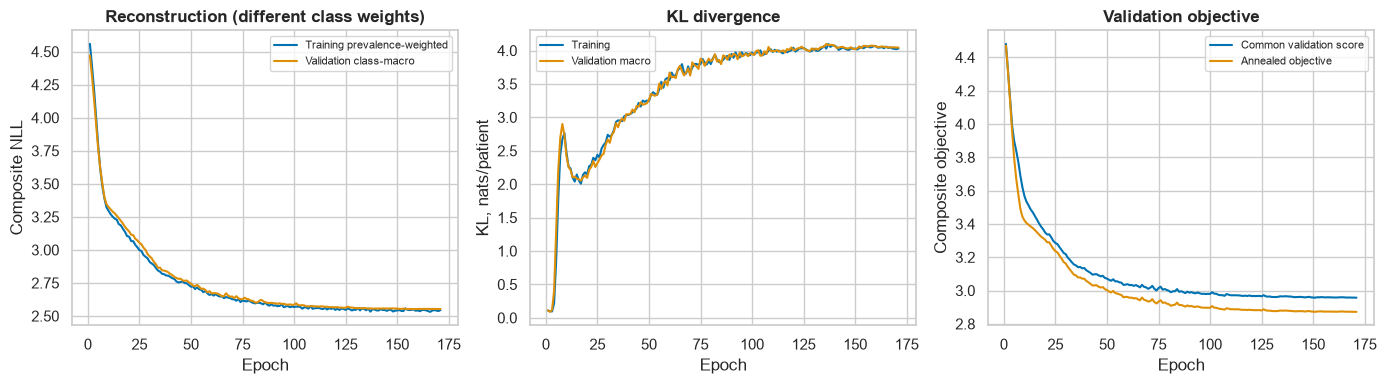

In [10]:
models, histories, experiment_rows = {}, {}, []
if RESUME_DIR is None:
    for i, config in enumerate(EXPERIMENTS):
        name = f"run_{i:02d}"
        model, history, row = fit_generator(config, name)
        models[name], histories[name] = model, history
        experiment_rows.append(row)
        print(name, "best epoch", row["best_epoch"], "validation score", round(row["validation_score"], 4))
else:
    restored_configs = []
    stored = pd.read_csv(RESUME_DIR/"metrics"/"experiment_training_comparison.csv")
    for row in stored.to_dict(orient="records"):
        name = row["experiment"]
        checkpoint = torch.load(RESUME_DIR/"checkpoints"/f"{name}.pt", map_location="cpu", weights_only=True)
        if checkpoint["csv_sha256"] != csv_sha256: raise ValueError("Checkpoint source fingerprint differs.")
        cfg = checkpoint["config"]
        restored_configs.append(cfg)
        model = CVAE(codec, checkpoint["condition_dim"], cfg["latent_dim"],
                     dropout=cfg.get("dropout", .05), joint_stage=cfg.get("joint_stage", False),
                     categorical_age=cfg.get("categorical_age", False)).to(DEVICE)
        model.load_state_dict(checkpoint["state_dict"], strict=True)
        model.eval()
        models[name] = model
        histories[name] = pd.read_csv(RESUME_DIR/"metrics"/f"{name}_history.csv")
        experiment_rows.append(row)
        shutil.copyfile(RESUME_DIR/"checkpoints"/f"{name}.pt", RUN_DIR/"checkpoints"/f"{name}.pt")
        histories[name].to_csv(RUN_DIR/"metrics"/f"{name}_history.csv", index=False)
    EXPERIMENTS = restored_configs
    print("Restored", len(models), "models. No training performed; original architecture/regularization retained.")
comparison = pd.DataFrame(experiment_rows)
best_name = comparison.sort_values("validation_score").iloc[0].experiment
if RESUME_DIR is not None and (RESUME_DIR/"metrics"/"tuning_selection.csv").is_file():
    ranking_path = RESUME_DIR/"metrics"/"tuning_selection.csv"
    best_name = pd.read_csv(ranking_path).iloc[0].experiment
    shutil.copyfile(ranking_path, RUN_DIR/"metrics"/"tuning_selection.csv")
best_model = models[best_name]
comparison.to_csv(RUN_DIR/"metrics"/"experiment_training_comparison.csv", index=False)
display(comparison.round(4))
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
h = histories[best_name]
axes[0].plot(h.epoch, h.train_rec, label="Training prevalence-weighted")
axes[0].plot(h.epoch, (h.rec_0+h.rec_1)/2, label="Validation class-macro")
axes[0].set(title="Reconstruction (different class weights)", xlabel="Epoch", ylabel="Composite NLL")
axes[1].plot(h.epoch, h.train_kl, label="Training")
axes[1].plot(h.epoch, (h.kl_0+h.kl_1)/2, label="Validation macro")
axes[1].set(title="KL divergence", xlabel="Epoch", ylabel="KL, nats/patient")
axes[2].plot(h.epoch, h.score, label="Common validation score")
axes[2].plot(h.epoch, h.val_own_objective, label="Annealed objective")
axes[2].set(title="Validation objective", xlabel="Epoch", ylabel="Composite objective")
for ax in axes: ax.legend(fontsize=8)
finish(fig, "training_diagnostics")

## 7. Conditional synthetic patient generation
## 8. Clinical constraint enforcement

Draw z~N(0,I), set Y=1, sample distributions directly and reject hard-rule failures.
Optional Race conditioning samples the empirical training **class-conditional** Race prior
and fixes decoded Race to that condition. It is faithful sampling, not demographic parity.
The generator does not fit separate tiny subgroup models.

Required minority counts come from the actual training split. Bounded generation may return
fewer patients than requested; shortages are never filled with invalid samples. Every proposal
records hard reasons, soft flags, retention and disposition. Exact training matches and
synthetic duplicates are excluded and audited, with batch surplus tracked separately.
Raw proposal memorization metrics are retained so filtering cannot hide copying.

With AUTO_TUNE enabled, the search compares the two age heads over matched training seeds,
then draws beta, dropout and learning rate from continuous ranges and tests class weighting.
The three best random trials are confirmed with a second training seed. Each trial uses
the same validation minority patients, generation seeds and retained sample budget.
The selection score weights age, race and joint stage TVD and penalizes size-stage flags
and rejection. These weights are experimental. Exact training matches and repeat samples
are filtered by the existing generator. The optional warm-start pair is diagnostic and
uses a matched low learning rate. Test data do not enter the search.


### Sampling, filtering and validation scoring functions

In [11]:
def sample_patients(model, n, outcome=1, age_logit_offset=0.):
    model.eval()
    condition = torch.full((n, 1), float(outcome), device=DEVICE)
    chosen_races = None
    if CONDITION_ON_RACE:
        races = codec.levels["Race"]
        p = train_df.loc[train_df.label == outcome, "Race"].value_counts(normalize=True).reindex(races, fill_value=0).to_numpy()
        chosen_races = np.random.choice(len(races), n, p=p)
        condition = torch.cat([condition, F.one_hot(torch.tensor(chosen_races, device=DEVICE), len(races)).float()], 1)
    with torch.no_grad():
        heads = model.decode(torch.randn(n, model.latent_dim, device=DEVICE), condition)
        discrete, dispersion, nb_logits, positive_logits, categorical, joint = heads
        values = {}
        for j, c in enumerate(NUM_COLS[:2]):
            logits = discrete[j]
            if j == 0 and outcome == 1 and age_logit_offset:
                in_band = (model.support_0 >= 61) & (model.support_0 <= 70)
                logits = logits + age_logit_offset * in_band.to(logits.dtype)
            idx = torch.distributions.Categorical(logits=logits).sample()
            values[c] = getattr(model, f"support_{j}")[idx].cpu().numpy().astype(int)
        examined = torch.distributions.NegativeBinomial(total_count=dispersion, logits=nb_logits).sample()
        positive = torch.distributions.Binomial(total_count=examined, logits=positive_logits).sample()
        values[NUM_COLS[2]], values[NUM_COLS[3]] = examined.cpu().numpy().astype(int), positive.cpu().numpy().astype(int)
        for j, c in enumerate(CAT_COLS):
            idx = torch.distributions.Categorical(logits=categorical[j]).sample().cpu().numpy()
            values[c] = np.asarray(codec.levels[c])[idx]
        if joint is not None:
            stage_rows = model.stage_indices[torch.distributions.Categorical(logits=joint).sample()].cpu().numpy()
            for k, col in enumerate(["T Stage", "N Stage", "6th Stage"]):
                values[col] = np.asarray(codec.levels[col])[stage_rows[:, k]]
        if CONDITION_ON_RACE: values["Race"] = np.asarray(races)[chosen_races]
    return pd.DataFrame(values)[FEATURES]

training_profiles = set(map(tuple, train_df[FEATURES].to_numpy()))
def generate_validated(model, requested, seed, age_logit_offset=0.):
    seed_everything(seed)
    frames, audits, retained_profiles = [], [], set()
    retained_n, proposed = 0, 0
    budget = max(GENERATION_BATCH, requested*MAX_PROPOSAL_MULTIPLIER)
    while retained_n < requested and proposed < budget:
        n = min(GENERATION_BATCH, budget-proposed)
        batch = sample_patients(model, n, age_logit_offset=age_logit_offset)
        hard, soft = engine.check(batch)
        valid = ~hard.any(axis=1)
        retained, dispositions = [], []
        for j, values in enumerate(batch.itertuples(index=False, name=None)):
            keep, disposition = False, "hard_rule_rejection"
            if valid.iloc[j]:
                if values in training_profiles: disposition = "exact_training_match"
                elif values in retained_profiles: disposition = "synthetic_duplicate"
                elif retained_n >= requested: disposition = "batch_surplus"
                else:
                    disposition, keep = "retained", True
                    retained_profiles.add(values)
                    retained_n += 1
            retained.append(keep)
            dispositions.append(disposition)
        audits.append(batch.assign(proposal_id=np.arange(proposed, proposed+n), hard_valid=valid,
                                   retained=retained, disposition=dispositions,
                                   hard_reasons=hard.apply(lambda r: "|".join(r.index[r.to_numpy()]), axis=1),
                                   soft_flags=soft.apply(lambda r: "|".join(r.index[r.to_numpy()]), axis=1)))
        frames.append(batch.loc[retained])
        proposed += n
    samples = pd.concat(frames, ignore_index=True) if frames else pd.DataFrame(columns=FEATURES)
    audit = pd.concat(audits, ignore_index=True) if audits else pd.DataFrame(columns=FEATURES+["hard_valid", "retained", "disposition", "hard_reasons", "soft_flags"])
    return samples, audit


def score_search_candidate(name, model=None):
    if model is None:
        model = models[name]
    reference = val_df.loc[val_df.label.eq(1)]
    if len(reference) < 2:
        raise ValueError("Tuning requires at least two positive validation patients.")
    association_columns = ["T Stage", "N Stage", "6th Stage"]
    def tv(left, right):
        p = left.value_counts(normalize=True)
        q = right.value_counts(normalize=True)
        return float(p.sub(q, fill_value=0).abs().sum()/2)
    def age_bin(frame):
        return pd.cut(frame.Age, AGE_BINS, include_lowest=True).astype(str)
    rows = []
    for seed in GENERATION_SEEDS:
        synthetic, audit = generate_validated(model, EVALUATION_SAMPLES, seed)
        valid = len(synthetic) == EVALUATION_SAMPLES
        row = {"experiment": name, "generation_seed": seed, "retained": len(synthetic),
               "proposal_age_tvd": tv(age_bin(reference), age_bin(audit)),
               "acceptance": float(audit.hard_valid.mean())}
        row["age_61_70_proposal_share"] = float(audit.Age.between(61, 70).mean())
        row["age_61_70_retained_share"] = float(synthetic.Age.between(61, 70).mean())
        if valid:
            row.update(age_tvd=tv(age_bin(reference), age_bin(synthetic)),
                       race_tvd=tv(reference.Race, synthetic.Race),
                       stage_tvd=tv(reference[association_columns], synthetic[association_columns]),
                       size_stage_flags=float(audit.loc[audit.retained, "soft_flags"].str.contains("literal_mm_T1_T3_mismatch", na=False).mean()),
                       unique_share=float(len(synthetic.drop_duplicates())/len(synthetic)))
            row["score"] = (.4*row["age_tvd"]+.2*row["race_tvd"]+.4*row["stage_tvd"]
                            + .2*row["size_stage_flags"] + .1*(1-row["acceptance"]))
        else:
            row["score"] = float("inf")
        rows.append(row)
    return rows


### Search and checkpoint selection

In [12]:
if tuning_active:
    search_rows = []
    def evaluate_trial(name):
        search_rows.extend(score_search_candidate(name))
        pd.DataFrame(search_rows).to_csv(RUN_DIR/"metrics"/"tuning_generation_seeds.csv", index=False)
        return float(np.mean([r["score"] for r in search_rows if r["experiment"] == name]))

    def train_trial(config):
        name = f"run_{len(models):02d}"
        model, history, row = fit_generator(config, name)
        models[name], histories[name] = model, history
        experiment_rows.append(row)
        EXPERIMENTS.append(config)
        return name, evaluate_trial(name)

    scores = {name: evaluate_trial(name) for name in models}
    architecture_scores = {
        categorical: np.mean([scores[f"run_{i:02d}"] for i, cfg in enumerate(EXPERIMENTS)
                              if cfg["categorical_age"] == categorical])
        for categorical in (False, True)
    }
    architecture_winner = min(architecture_scores, key=architecture_scores.get)
    print("Paired architecture scores:", architecture_scores)
    rng = np.random.default_rng(SEED)
    for _ in range(SEARCH_TRIALS):
        config = {**BASE_CONFIG, "categorical_age": architecture_winner,
                  "beta": float(rng.uniform(*BETA_RANGE)), "dropout": float(rng.uniform(*DROPOUT_RANGE)),
                  "lr": float(np.exp(rng.uniform(*np.log(LR_RANGE)))),
                  "class_weighted": bool(rng.integers(2))}
        name, score = train_trial(config)
        scores[name] = score

    # Confirm the top three randomized settings with the second training seed.
    finalists = sorted((name for name in scores if int(name.split("_")[1]) >= 2*len(SEARCH_SEEDS)),
                       key=scores.get)[:3]
    selection = {name: scores[name] for name in scores if int(name.split("_")[1]) < 2*len(SEARCH_SEEDS)}
    for name in finalists:
        config = EXPERIMENTS[int(name.split("_")[1])]
        repeat, repeat_score = train_trial({**config, "seed": SEARCH_SEEDS[1]})
        selection[name] = (scores[name]+repeat_score)/2

    if SEARCH_SEEDS:
        warm_source = Path(WARM_START_RUN) if WARM_START_RUN is not None else RUN_DIR
        checkpoint_name = "run_01.pt" if WARM_START_RUN is not None else "run_00.pt"
        checkpoint_path = warm_source/"checkpoints"/checkpoint_name
        if checkpoint_path.is_file():
            prior = json.loads((warm_source/"split_indices.json").read_text(encoding="utf-8"))
            spec = json.loads((warm_source/"checkpoints"/"preprocessor_spec.json").read_text(encoding="utf-8"))
            if (prior["csv_sha256"] != csv_sha256 or prior["index_kind"] != "task_position"
                    or any(prior[k] != splits[k].tolist() for k in ("train", "validation", "test"))
                    or spec["levels"] != codec.levels or spec["features"] != FEATURES
                    or spec["condition_on_race"] != CONDITION_ON_RACE):
                raise ValueError("Warm-start source split or preprocessing differs.")
            paired = {**BASE_CONFIG, "categorical_age": architecture_winner, "lr": .0005}
            scratch, scratch_score = train_trial(paired)
            warm, warm_score = train_trial({**paired, "warm_start": str(checkpoint_path)})
            print("Matched scratch/warm-start scores:", scratch_score, warm_score)
        else:
            print("Warm-start checkpoint unavailable:", checkpoint_path)

    # Compare paired architecture means, then paired finalist means.
    for categorical in (False, True):
        names = [f"run_{i:02d}" for i in range(2*len(SEARCH_SEEDS))
                 if EXPERIMENTS[i]["categorical_age"] == categorical]
        representative = min(names, key=scores.get)
        for name in names:
            selection.pop(name, None)
        selection[representative] = architecture_scores[categorical]
    ranked = pd.DataFrame([{"experiment": name, "selection_score": score}
                           for name, score in selection.items()]).sort_values("selection_score")
    ranked.to_csv(RUN_DIR/"metrics"/"tuning_selection.csv", index=False)
    display(ranked)
    if not np.isfinite(ranked.iloc[0].selection_score):
        raise RuntimeError("No candidate generated the requested validation sample budget.")
    best_name = ranked.iloc[0].experiment
    best_model = models[best_name]
    comparison = pd.DataFrame(experiment_rows)
    comparison.to_csv(RUN_DIR/"metrics"/"experiment_training_comparison.csv", index=False)
    print("Selected by synthetic validation fidelity:", best_name)


### Generate the selected model’s synthetic cohorts

In [13]:
n_majority, n_minority = int(train_df.label.eq(0).sum()), int(train_df.label.eq(1).sum())
assert all(r in {1, 2, 3} for r in RATIOS) and len(RATIOS) == len(set(RATIOS))
needed = {r: max(0, math.ceil(n_majority/r)-n_minority) for r in RATIOS}
print("Real training counts:", {0: n_majority, 1: n_minority}, "synthetic needed:", needed)
generated, generation_audits = {}, {}
for ratio, requested in needed.items():
    generated[ratio], generation_audits[ratio] = generate_validated(best_model, requested, SEED+100+ratio)
    audit = generation_audits[ratio]
    audit.to_csv(RUN_DIR/"audit"/f"proposals_ratio_{ratio}.csv", index=False)
    print(f"Ratio {ratio}:1: requested={requested}, retained={len(generated[ratio])}, proposals={len(audit)}")
    if len(generated[ratio]) < requested: warnings.warn(f"Ratio {ratio}: generation budget exhausted.")
quality_samples, quality_audit = generate_validated(best_model, EVALUATION_SAMPLES, SEED+200)
quality_audit.to_csv(RUN_DIR/"audit"/"quality_proposals.csv", index=False)
if len(quality_samples) < 30: raise RuntimeError("Too few valid diagnostic samples; inspect saved proposal audits.")
real_minority = train_df.loc[train_df.label == 1, FEATURES].reset_index(drop=True)
validation_minority = val_df.loc[val_df.label == 1, FEATURES].reset_index(drop=True)

Real training counts: {0: 1805, 1: 287} synthetic needed: {3: 315, 2: 616}
Ratio 3:1: requested=315, retained=315, proposals=512
Ratio 2:1: requested=616, retained=616, proposals=1024


## 8. Synthetic data quality assessment

Training minority patients are the primary reference; real validation minority patients
provide an independent reference. KS is descriptive for discrete values; p-values do not
serve as acceptance criteria. Joint associations: numeric/numeric = Spearman; category/category
= Cramér's V; mixed pairs = correlation ratio η. These different measures are not causal
or interchangeable. Compare observed dependencies, not the prompt's approximate correlations.

The cross-validated **domain detector** distinguishes real versus synthetic records; it is
an auxiliary quality diagnostic, not a new clinical baseline. Distinct generated rows and
training rows are used once each. Detector preprocessing is frozen generator-training scaling.
Gower-style distances average normalized numerical differences and categorical mismatches.
Small nearest-neighbor distances alone do not prove privacy leakage or memorization.

### Fidelity and diversity functions

In [14]:
def total_variation(real, synthetic, column):
    levels = sorted(set(real[column]) | set(synthetic[column]))
    p = real[column].value_counts(normalize=True).reindex(levels, fill_value=0)
    q = synthetic[column].value_counts(normalize=True).reindex(levels, fill_value=0)
    return float((p-q).abs().sum()/2)

def marginal_metrics(real, synthetic):
    rows = []
    for c in NUM_COLS:
        a, b = real[c], synthetic[c]
        rows.append({"feature": c, "kind": "numeric", "wasserstein": stats.wasserstein_distance(a, b),
                     "ks_statistic": stats.ks_2samp(a, b).statistic,
                     "median_real": a.median(), "median_synthetic": b.median(),
                     "variance_real": a.var(), "variance_synthetic": b.var(),
                     "skew_real": a.skew(), "skew_synthetic": b.skew(),
                     **{f"q{int(q*100)}_{name}": s.quantile(q) for q in [.05, .25, .75, .95]
                        for name, s in [("real", a), ("synthetic", b)]}})
    for c in CAT_COLS: rows.append({"feature": c, "kind": "categorical", "tvd": total_variation(real, synthetic, c)})
    return pd.DataFrame(rows)

def association_matrix(frame):
    result = pd.DataFrame(np.eye(len(FEATURES)), index=FEATURES, columns=FEATURES)
    for i, a in enumerate(FEATURES):
        for b in FEATURES[i+1:]:
            if a in NUM_COLS and b in NUM_COLS:
                value = frame[a].corr(frame[b], method="spearman")
            elif a in CAT_COLS and b in CAT_COLS:
                table = pd.crosstab(frame[a], frame[b])
                value = np.sqrt(stats.chi2_contingency(table, correction=False)[0]/(len(frame)*(min(table.shape)-1))) if min(table.shape) > 1 else np.nan
            else:
                number, category = (a, b) if a in NUM_COLS else (b, a)
                means = frame.groupby(category, observed=True)[number].agg(["size", "mean"])
                denominator = ((frame[number]-frame[number].mean())**2).sum()
                value = np.sqrt((means["size"]*(means["mean"]-frame[number].mean())**2).sum()/denominator) if denominator > 0 else np.nan
            result.loc[a, b] = result.loc[b, a] = value
    return result

def association_error(a, b):
    upper = np.triu_indices(len(FEATURES), 1)
    return float(np.nanmean(np.abs(a.to_numpy()[upper]-b.to_numpy()[upper])))

def detector_auc(real, synthetic):
    n = min(len(real), len(synthetic), 600)
    if n < 10: return np.nan
    a, b = real.sample(n, random_state=SEED), synthetic.sample(n, random_state=SEED)
    inputs = codec.encode(pd.concat([a, b], ignore_index=True).assign(label=1))[0].numpy()
    domain = np.r_[np.zeros(n), np.ones(n)]
    detector = HistGradientBoostingClassifier(max_iter=60, max_leaf_nodes=7, l2_regularization=2, random_state=SEED)
    cv = StratifiedKFold(3, shuffle=True, random_state=SEED)
    return float(cross_val_score(detector, inputs, domain, scoring="roc_auc", cv=cv, n_jobs=1).mean())

def gower_distances(first, second):
    distances = np.zeros((len(first), len(second)), dtype=np.float32)
    for c in NUM_COLS:
        low, high = codec.bounds[c]
        distances += np.minimum(np.abs(first[c].to_numpy()[:, None]-second[c].to_numpy()[None, :])/max(high-low, 1), 1)
    for c in CAT_COLS:
        distances += first[c].to_numpy()[:, None] != second[c].to_numpy()[None, :]
    return distances/len(FEATURES)

def diversity_metrics(real, synthetic):
    distances = gower_distances(synthetic, real)
    within = gower_distances(synthetic, synthetic)
    np.fill_diagonal(within, np.inf)
    real_within = gower_distances(real, real)
    np.fill_diagonal(real_within, np.inf)
    reference = real_within.min(1)
    threshold = float(np.quantile(reference, .05))
    exact = np.mean([tuple(v) in training_profiles for v in synthetic[FEATURES].to_numpy()])
    return {"exact_training_match_rate": exact, "synthetic_duplicate_rate": synthetic.duplicated(FEATURES).mean(),
            "median_synthetic_to_training_nn": float(np.median(distances.min(1))),
            "median_synthetic_to_synthetic_nn": float(np.median(within.min(1))),
            "median_real_leave_one_out_nn": float(np.median(reference)),
            "near_duplicate_threshold_real_q05": threshold,
            "near_duplicate_rate": float((distances.min(1) <= threshold).mean()),
            "median_validation_to_training_nn": float(np.median(gower_distances(validation_minority, real).min(1)))}


In [15]:
fidelity = marginal_metrics(real_minority, quality_samples)
validation_fidelity = marginal_metrics(validation_minority, quality_samples)
real_assoc, synthetic_assoc = association_matrix(real_minority), association_matrix(quality_samples)
association_mae, domain_auc = association_error(real_assoc, synthetic_assoc), detector_auc(real_minority, quality_samples)
memorization = diversity_metrics(real_minority, quality_samples)
raw_exact_match_rate = float(np.mean([tuple(v) in training_profiles for v in quality_audit[FEATURES].to_numpy()]))
fidelity.to_csv(RUN_DIR/"metrics"/"marginal_fidelity_training.csv", index=False)
validation_fidelity.to_csv(RUN_DIR/"metrics"/"marginal_fidelity_validation.csv", index=False)
real_assoc.to_csv(RUN_DIR/"metrics"/"real_associations.csv")
synthetic_assoc.to_csv(RUN_DIR/"metrics"/"synthetic_associations.csv")
save_json({**memorization, "raw_exact_training_match_rate": raw_exact_match_rate,
           "association_mae": association_mae, "domain_detector_auc": domain_auc}, RUN_DIR/"metrics"/"joint_diversity.json")
display(fidelity.round(3))
display(pd.Series(memorization).to_frame("value").round(4))
print("Association MAE:", round(association_mae, 3), "domain detector AUC:", round(domain_auc, 3))

,feature,kind,wasserstein,ks_statistic,median_real,median_synthetic,variance_real,variance_synthetic,skew_real,skew_synthetic,q5_real,q5_synthetic,q25_real,q25_synthetic,q75_real,q75_synthetic,q95_real,q95_synthetic,tvd
0,Age,numeric,1.639,0.128,58.0,55.0,95.467,84.465,-0.474,-0.344,38.0,37.0,49.0,48.0,64.0,61.0,69.0,68.00,NaN
1,Tumor Size,numeric,4.447,0.084,33.0,30.0,642.790,369.576,1.334,0.950,12.0,12.0,20.0,21.0,51.0,47.0,88.5,76.00,NaN
2,Regional Node Examined,numeric,0.720,0.056,15.0,14.0,85.573,81.143,1.164,1.055,3.0,4.0,10.0,9.0,20.0,20.0,31.0,33.00,NaN
3,Reginol Node Positive,numeric,1.342,0.096,5.0,4.0,64.568,56.782,1.512,2.201,1.0,1.0,2.0,2.0,12.0,9.0,24.0,22.05,NaN
4,Race,categorical,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.032
5,Marital Status,categorical,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.066
6,T Stage,categorical,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.059
7,N Stage,categorical,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.069
8,6th Stage,categorical,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.101
9,Grade,categorical,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.119


,value
exact_training_match_rate,0.0000
synthetic_duplicate_rate,0.0000
median_synthetic_to_training_nn,0.0530
median_synthetic_to_synthetic_nn,0.0338
median_real_leave_one_out_nn,0.0655
near_duplicate_threshold_real_q05,0.0123
near_duplicate_rate,0.0583
median_validation_to_training_nn,0.0390


Association MAE: 0.087 domain detector AUC: 0.685


### Marginals and clinically important dependencies

Histograms use original units and densities because sample sizes differ. KDE is deliberately
omitted for these integer-valued and count features. Conditional medians and joint association
differences can expose distortions hidden by matching marginal distributions.

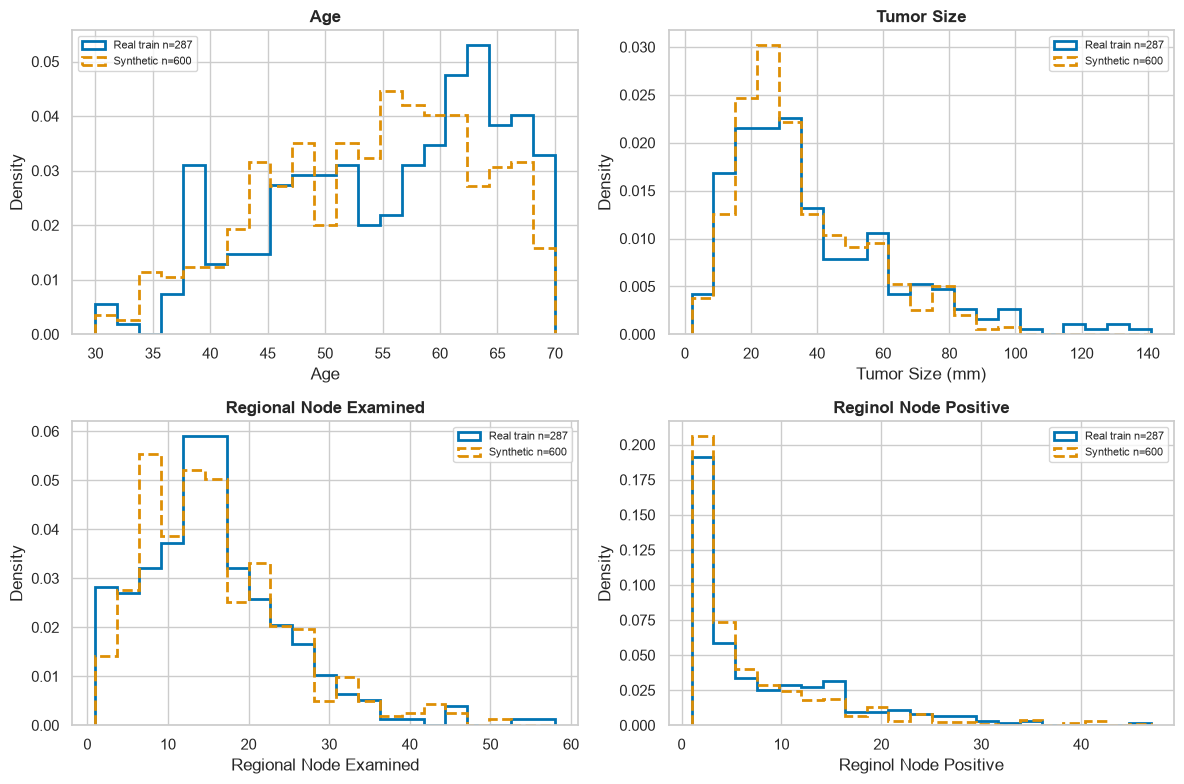

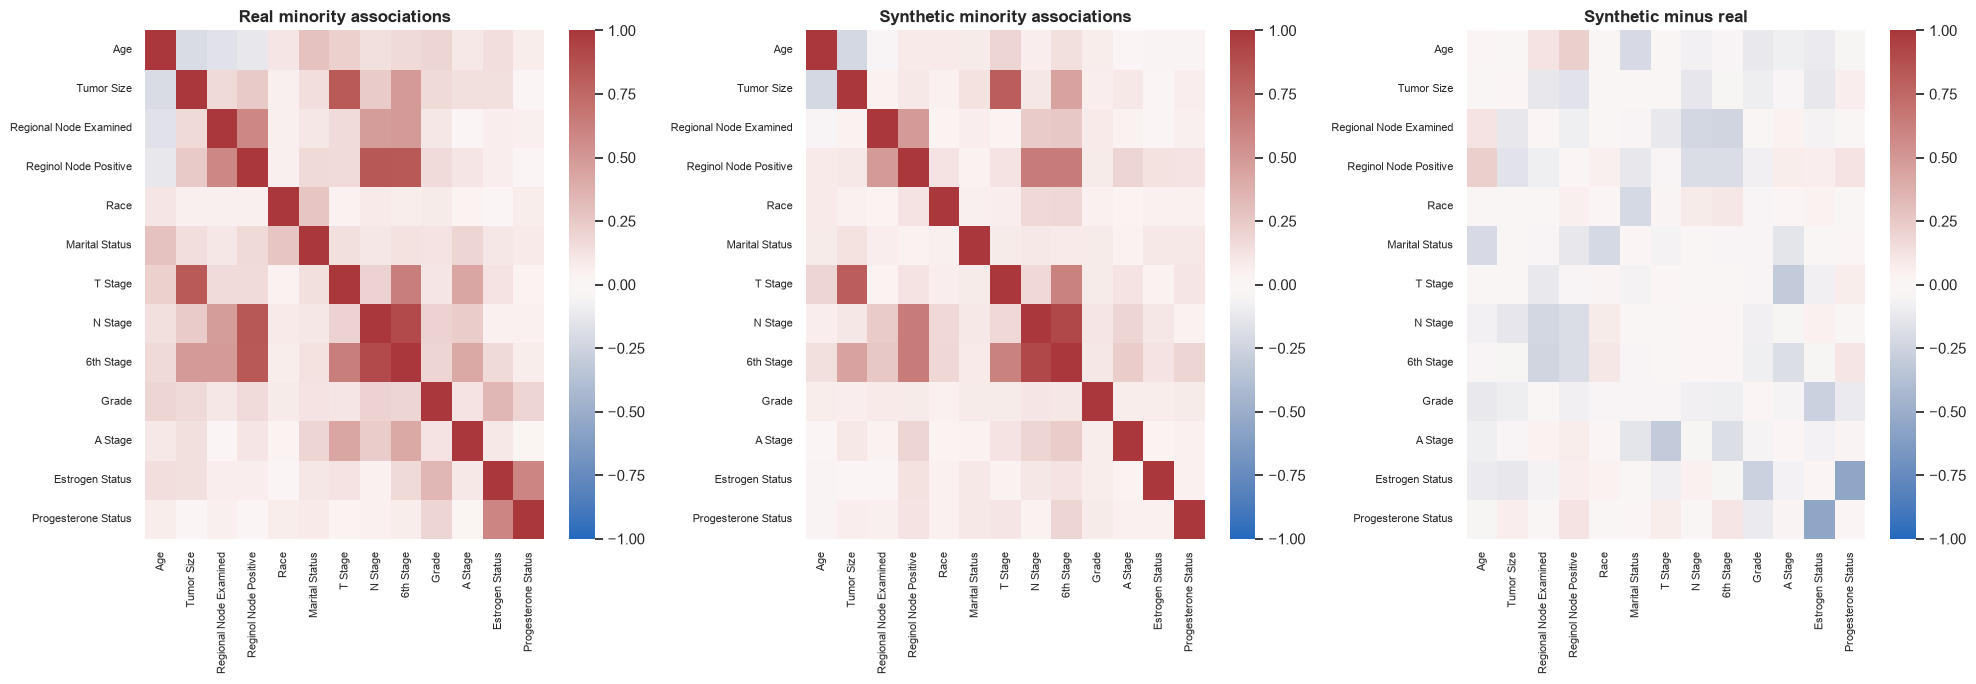

,feature,level,real_n,synthetic_n,real_share,synthetic_share,rare_real_level
1,Race,"Other (American Indian/AK Native, Asian/Pacifi...",10,29,0.035,0.048,True
5,Marital Status,Separated,8,5,0.028,0.008,True
18,6th Stage,IIIB,11,12,0.038,0.020,True
22,Grade,Undifferentiated; anaplastic; Grade IV,6,9,0.021,0.015,True
23,Grade,Well differentiated; Grade I,18,59,0.063,0.098,True
24,A Stage,Distant,19,26,0.066,0.043,True


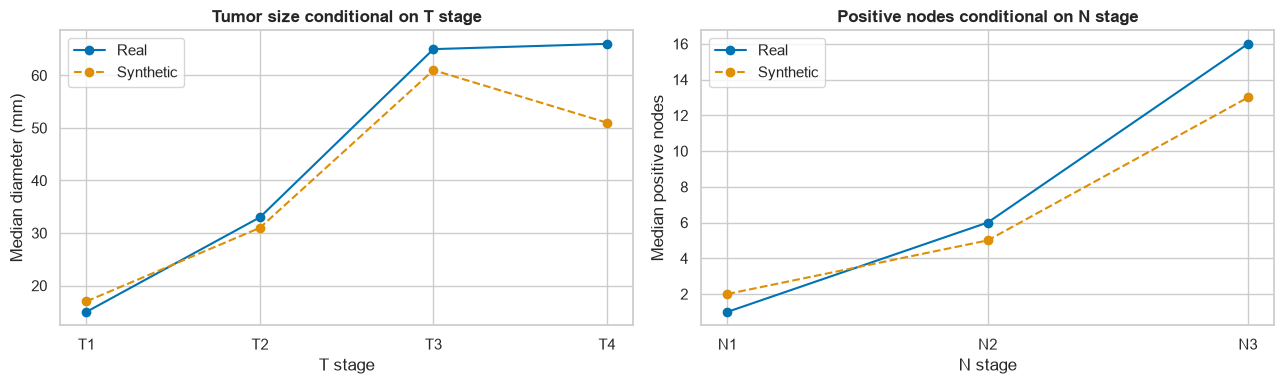

In [16]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for ax, c in zip(axes.flat, NUM_COLS):
    bins = np.linspace(min(real_minority[c].min(), quality_samples[c].min()), max(real_minority[c].max(), quality_samples[c].max())+1, 22)
    ax.hist(real_minority[c], bins=bins, density=True, histtype="step", linewidth=2, label=f"Real train n={len(real_minority)}")
    ax.hist(quality_samples[c], bins=bins, density=True, histtype="step", linewidth=2, linestyle="--", label=f"Synthetic n={len(quality_samples)}")
    ax.set(title=c, xlabel=c+(" (mm)" if c == "Tumor Size" else ""), ylabel="Density")
    ax.legend(fontsize=8)
finish(fig, "numeric_fidelity")
fig, axes = plt.subplots(1, 3, figsize=(20, 7))
for ax, matrix, title in zip(axes, [real_assoc, synthetic_assoc, synthetic_assoc-real_assoc],
                            ["Real minority associations", "Synthetic minority associations", "Synthetic minus real"]):
    sns.heatmap(matrix, ax=ax, cmap="vlag", center=0, vmin=-1, vmax=1, xticklabels=True, yticklabels=True)
    ax.set_title(title)
    ax.tick_params(labelsize=8)
finish(fig, "joint_associations")
frequency_rows = []
for c in CAT_COLS:
    for level in codec.levels[c]:
        a, b = int(real_minority[c].eq(level).sum()), int(quality_samples[c].eq(level).sum())
        frequency_rows.append({"feature": c, "level": level, "real_n": a, "synthetic_n": b,
                               "real_share": a/len(real_minority), "synthetic_share": b/len(quality_samples),
                               "rare_real_level": a < MIN_SUBGROUP_N})
category_frequencies = pd.DataFrame(frequency_rows)
category_frequencies.to_csv(RUN_DIR/"metrics"/"category_frequencies.csv", index=False)
display(category_frequencies.loc[category_frequencies.rare_real_level].round(3))
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for frame, label, style in [(real_minority, "Real", "-"), (quality_samples, "Synthetic", "--")]:
    sizes = frame.groupby("T Stage")["Tumor Size"].median().reindex(ORDERED["T Stage"])
    nodes = frame.groupby("N Stage")["Reginol Node Positive"].median().reindex(ORDERED["N Stage"])
    axes[0].plot(sizes.index, sizes, marker="o", linestyle=style, label=label)
    axes[1].plot(nodes.index, nodes, marker="o", linestyle=style, label=label)
axes[0].set(title="Tumor size conditional on T stage", xlabel="T stage", ylabel="Median diameter (mm)")
axes[1].set(title="Positive nodes conditional on N stage", xlabel="N stage", ylabel="Median positive nodes")
for ax in axes: ax.legend()
finish(fig, "conditional_clinical_relationships")

### Clinical validity report

Count valid/invalid rows and rates per hard rule, before and after filtering. Soft flags
remain visible on retained samples. Corrections are always zero. Missing clinical variables
remain unresolved even when all exported hard checks pass.

In [17]:
clinical_rows = []
for name, frame in [("raw_quality_proposals", quality_audit), ("retained_quality", quality_samples)]+[(f"ratio_{r}", f) for r, f in generated.items()]:
    hard, soft = engine.check(frame)
    for kind, flags in [("hard", hard), ("conditional_or_soft", soft)]:
        for rule in flags:
            invalid = int(flags[rule].sum())
            clinical_rows.append({"population": name, "rule_type": kind, "rule": rule, "n": len(frame),
                                  "valid_n": len(frame)-invalid, "invalid_n": invalid,
                                  "flag_rate": invalid/len(frame) if len(frame) else np.nan, "corrections_n": 0})
clinical_report = pd.DataFrame(clinical_rows)
clinical_report.to_csv(RUN_DIR/"metrics"/"clinical_validation.csv", index=False)
save_json({"unresolved": UNRESOLVED, "assume_M0": ASSUME_M0_FOR_STAGE_CHECK,
           "literal_mm_rejection": ENABLE_SIZE_STAGE_REJECTION}, RUN_DIR/"metrics"/"unresolved_clinical_checks.json")
display(clinical_report.loc[(clinical_report.invalid_n > 0) | (clinical_report.rule == "positive_le_examined")].round(3))
display(quality_audit.disposition.value_counts().to_frame("proposals"))

,population,rule_type,rule,n,valid_n,invalid_n,flag_rate,corrections_n
5,raw_quality_proposals,hard,Regional Node Examined:training_range,1024,1011,13,0.013,0
7,raw_quality_proposals,hard,Reginol Node Positive:training_range,1024,892,132,0.129,0
11,raw_quality_proposals,hard,positive_le_examined,1024,1024,0,0.000,0
22,raw_quality_proposals,conditional_or_soft,literal_mm_T1_T3_mismatch,1024,840,184,0.180,0
35,retained_quality,hard,positive_le_examined,600,600,0,0.000,0
46,retained_quality,conditional_or_soft,literal_mm_T1_T3_mismatch,600,494,106,0.177,0
59,ratio_3,hard,positive_le_examined,315,315,0,0.000,0
70,ratio_3,conditional_or_soft,literal_mm_T1_T3_mismatch,315,261,54,0.171,0
83,ratio_2,hard,positive_le_examined,616,616,0,0.000,0
94,ratio_2,conditional_or_soft,literal_mm_T1_T3_mismatch,616,519,97,0.157,0


,proposals
disposition,
retained,600
batch_surplus,291
hard_rule_rejection,132
exact_training_match,1


## 9. Fairness and subgroup analysis

Race, existing EDA age bins and Age × Race: compare counts, shares, clinical distributions,
diversity and hard rejection rates. Wilson 95% intervals describe within-sample proportions;
bootstrap intervals describe numeric median differences. These do not include model-training
uncertainty. Rare groups are flagged rather than treated as reliable. Preserving demographic
representation can preserve historical biases; downstream fairness needs real held-out patients.

### Subgroup statistics functions

In [18]:
def demographic_groups(frame):
    age = pd.cut(frame.Age, AGE_BINS, include_lowest=True).astype(str)
    race = frame.Race.astype(str)
    return {"Race": race, "Age group": age, "Age x Race": age+" | "+race}
def wilson(k, n):
    if n == 0: return np.nan, np.nan
    p, z = k/n, 1.96
    center = (p+z*z/(2*n))/(1+z*z/n)
    half = z*np.sqrt(p*(1-p)/n+z*z/(4*n*n))/(1+z*z/n)
    return center-half, center+half
def bootstrap_median_difference(a, b):
    if min(len(a), len(b)) < 2: return np.nan, np.nan
    rng = np.random.default_rng(SEED)
    values = [np.median(rng.choice(b, len(b), replace=True))-np.median(rng.choice(a, len(a), replace=True)) for _ in range(BOOTSTRAPS)]
    return tuple(np.quantile(values, [.025, .975]))


,dimension,group,real_n,synthetic_n,real_share,synthetic_share,representation_difference,real_share_low,real_share_high,synthetic_share_low,synthetic_share_high,proposals,hard_pass_n,rejection_rate,hard_pass_low,hard_pass_high,small_group,synthetic_unique_fraction,median_synthetic_to_group_training_nn
0,Race,Black,38,60,0.132,0.100,-0.032,0.098,0.177,0.078,0.127,96,85,0.115,0.806,0.935,False,1.0,0.125
1,Race,"Other (American Indian/AK Native, Asian/Pacifi...",10,29,0.035,0.048,0.013,0.019,0.063,0.034,0.069,67,51,0.239,0.647,0.847,True,1.0,0.228
2,Race,White,239,511,0.833,0.852,0.019,0.785,0.871,0.821,0.878,861,756,0.122,0.854,0.898,False,1.0,0.043
3,Age group,"(-0.001, 40.0]",29,53,0.101,0.088,-0.013,0.071,0.141,0.068,0.114,87,75,0.138,0.774,0.919,False,1.0,0.114
4,Age group,"(40.0, 50.0]",66,159,0.230,0.265,0.035,0.185,0.282,0.231,0.302,258,220,0.147,0.804,0.891,False,1.0,0.094
5,Age group,"(50.0, 60.0]",76,222,0.265,0.370,0.105,0.217,0.319,0.332,0.409,380,334,0.121,0.842,0.908,False,1.0,0.098
6,Age group,"(60.0, 70.0]",116,166,0.404,0.277,-0.128,0.349,0.462,0.242,0.314,299,263,0.120,0.838,0.912,False,1.0,0.091
7,Age x Race,"(-0.001, 40.0] | Black",7,1,0.024,0.002,-0.023,0.012,0.049,0.000,0.009,6,3,0.500,0.188,0.812,True,1.0,0.357
8,Age x Race,"(-0.001, 40.0] | Other (American Indian/AK Nat...",2,2,0.007,0.003,-0.004,0.002,0.025,0.001,0.012,7,5,0.286,0.359,0.918,True,1.0,0.303
9,Age x Race,"(-0.001, 40.0] | White",20,50,0.070,0.083,0.014,0.046,0.105,0.064,0.108,74,67,0.095,0.817,0.953,False,1.0,0.113


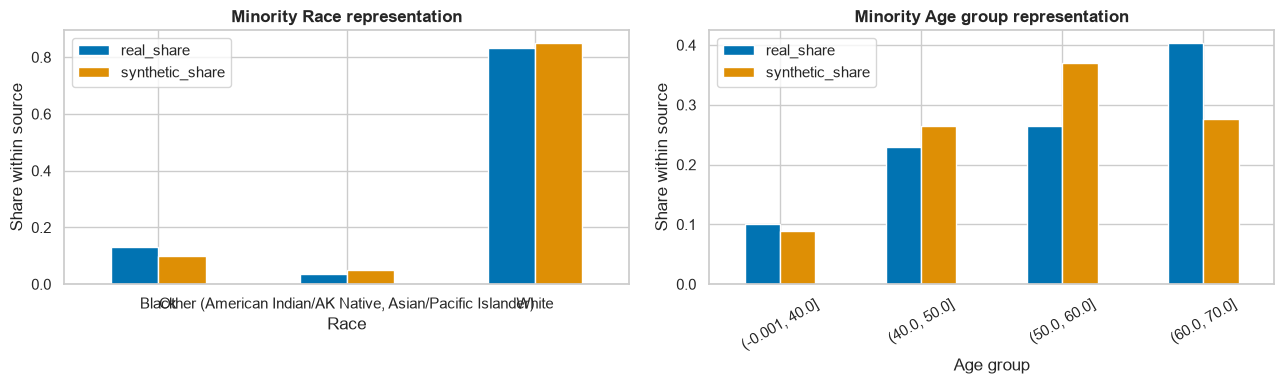

Flagged small groups: 9 of 19


In [19]:
real_groups, syn_groups, proposal_groups = [demographic_groups(f) for f in [real_minority, quality_samples, quality_audit]]
subgroup_rows, subgroup_fidelity_rows = [], []
for dimension in real_groups:
    rg, sg, pg = real_groups[dimension], syn_groups[dimension], proposal_groups[dimension]
    for level in sorted(set(rg) | set(sg) | set(pg)):
        nr, ns = int(rg.eq(level).sum()), int(sg.eq(level).sum())
        proposals = quality_audit.loc[pg == level]
        hard_pass = int(proposals.hard_valid.sum())
        low, high = wilson(hard_pass, len(proposals))
        rlow, rhigh = wilson(nr, len(real_minority))
        slow, shigh = wilson(ns, len(quality_samples))
        sr, ss = nr/len(real_minority), ns/len(quality_samples)
        a, b = real_minority.loc[rg == level], quality_samples.loc[sg == level]
        subgroup_rows.append({"dimension": dimension, "group": level, "real_n": nr, "synthetic_n": ns,
                              "real_share": sr, "synthetic_share": ss, "representation_difference": ss-sr,
                              "real_share_low": rlow, "real_share_high": rhigh,
                              "synthetic_share_low": slow, "synthetic_share_high": shigh,
                              "proposals": len(proposals), "hard_pass_n": hard_pass,
                              "rejection_rate": 1-hard_pass/len(proposals) if len(proposals) else np.nan,
                              "hard_pass_low": low, "hard_pass_high": high,
                              "small_group": min(nr, ns) < MIN_SUBGROUP_N,
                              "synthetic_unique_fraction": 1-b.duplicated(FEATURES).mean() if ns else np.nan,
                              "median_synthetic_to_group_training_nn": float(np.median(gower_distances(b, a).min(1))) if nr and ns else np.nan})
        if nr and ns:
            for c in NUM_COLS:
                lo, hi = bootstrap_median_difference(a[c].to_numpy(), b[c].to_numpy())
                subgroup_fidelity_rows.append({"dimension": dimension, "group": level, "feature": c,
                                               "wasserstein": stats.wasserstein_distance(a[c], b[c]),
                                               "real_median": a[c].median(), "synthetic_median": b[c].median(),
                                               "median_difference_low": lo, "median_difference_high": hi})
            for c in CAT_COLS:
                subgroup_fidelity_rows.append({"dimension": dimension, "group": level, "feature": c, "tvd": total_variation(a, b, c)})
subgroups, subgroup_fidelity = pd.DataFrame(subgroup_rows), pd.DataFrame(subgroup_fidelity_rows)
subgroups.to_csv(RUN_DIR/"metrics"/"subgroup_representation_rejection.csv", index=False)
subgroup_fidelity.to_csv(RUN_DIR/"metrics"/"subgroup_fidelity.csv", index=False)
display(subgroups.round(3))
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, dimension in zip(axes, ["Race", "Age group"]):
    table = subgroups.loc[subgroups.dimension == dimension].set_index("group")
    table[["real_share", "synthetic_share"]].plot.bar(ax=ax, rot=30 if dimension == "Age group" else 0)
    ax.set(title=f"Minority {dimension} representation", xlabel=dimension, ylabel="Share within source")
finish(fig, "demographic_representation")
print("Flagged small groups:", int(subgroups.small_group.sum()), "of", len(subgroups))

## 10. Latent-space analysis and interpretability

PCA fits only training posterior means. Colors show associations, not mechanisms. Traverse
each latent coordinate at −2, −1, 0, 1, 2 while holding the others at zero and Y=1. Export
decoded expectations/probabilities, including stage distributions. Fractional expected counts
are diagnostics, not generated patient records. Traversal hard checks use sampled patients;
an average vector is not itself a clinically interpretable patient.

Changing Y at fixed z measures decoder sensitivity, not the causal effect of survival.
When Race conditioning is enabled, traversals fix the most frequent training Race.
Compare same-width latent spaces across seeds using distance-geometry correlation since
individual coordinates can rotate or permute. Also compare two generation seeds for the
selected model to distinguish proposal variability from training variability.

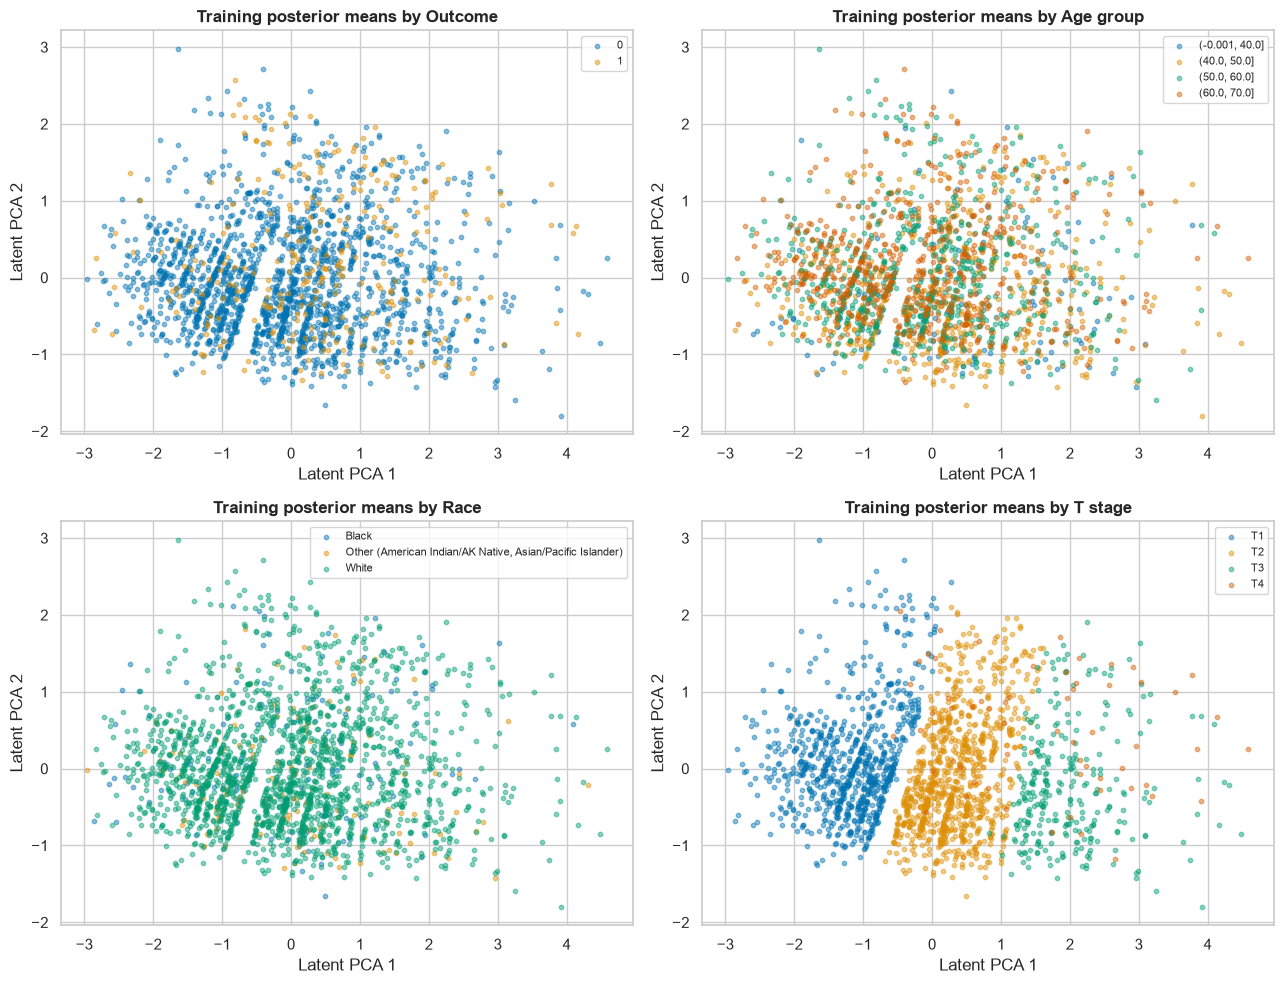

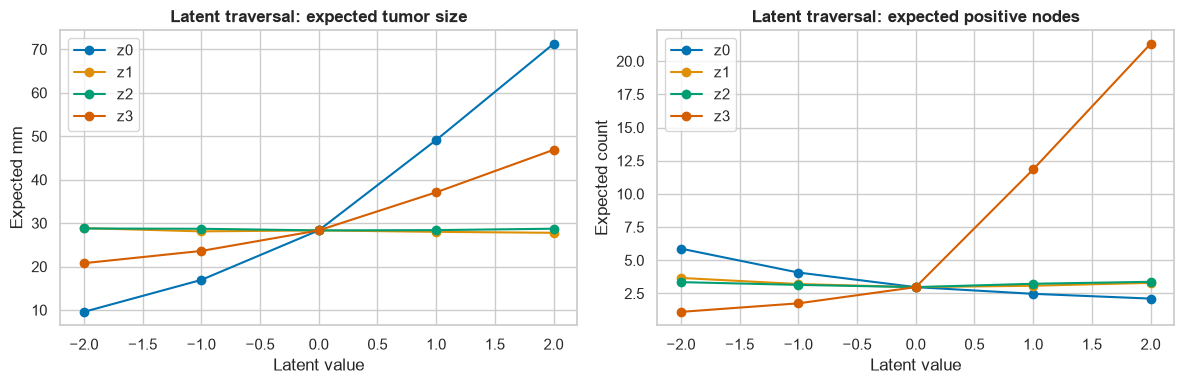

,Y1_minus_Y0_expectation
Age,0.287
Tumor Size,2.277
Regional Node Examined,-0.640
Reginol Node Positive,0.519


,experiment,distance_geometry_spearman
0,run_01,0.977884
1,run_02,0.984667
2,run_03,0.973675
3,run_04,0.992016
4,run_05,0.963438
5,run_06,0.948036
6,run_07,0.984391
7,run_08,0.966231
8,run_09,0.986787
9,run_10,0.940034


In [20]:
def posterior_means(model, tensors):
    model.eval()
    with torch.no_grad(): return model.encode(tensors[0].to(DEVICE), tensors[2].to(DEVICE))[0].cpu().numpy()
latent = posterior_means(best_model, train_tensors)
latent_pca = PCA(2, random_state=SEED).fit_transform(latent)
fig, axes = plt.subplots(2, 2, figsize=(13, 10))
views = {"Outcome": train_df.label.astype(str), "Age group": demographic_groups(train_df)["Age group"],
         "Race": train_df.Race, "T stage": train_df["T Stage"]}
for ax, (name, colors) in zip(axes.flat, views.items()):
    for level in sorted(colors.unique()):
        mask = colors.eq(level).to_numpy()
        ax.scatter(latent_pca[mask, 0], latent_pca[mask, 1], s=10, alpha=.45, label=str(level))
    ax.set(title=f"Training posterior means by {name}", xlabel="Latent PCA 1", ylabel="Latent PCA 2")
    ax.legend(fontsize=8)
finish(fig, "latent_pca")

def expected_decoding(model, z, outcome, sample=False):
    condition = torch.full((len(z), 1), float(outcome), device=DEVICE)
    if CONDITION_ON_RACE:
        race_index = codec.levels["Race"].index(train_df.Race.mode().iloc[0])
        race = F.one_hot(torch.full((len(z),), race_index, device=DEVICE), len(codec.levels["Race"])).float()
        condition = torch.cat([condition, race], 1)
    with torch.no_grad():
        discrete, dispersion, nb_logits, positive_logits, categorical, joint = model.decode(z, condition)
        values = {}
        for j, c in enumerate(NUM_COLS[:2]):
            support = getattr(model, f"support_{j}")
            v = support[torch.distributions.Categorical(logits=discrete[j]).sample()] if sample else (discrete[j].softmax(1)*support).sum(1)
            values[c] = v.cpu().numpy()
        nb = torch.distributions.NegativeBinomial(total_count=dispersion, logits=nb_logits)
        examined = nb.sample() if sample else nb.mean
        positive = torch.distributions.Binomial(total_count=examined, logits=positive_logits).sample() if sample else examined*positive_logits.sigmoid()
        values[NUM_COLS[2]], values[NUM_COLS[3]] = examined.cpu().numpy(), positive.cpu().numpy()
        for j, c in enumerate(CAT_COLS):
            if sample:
                idx = torch.distributions.Categorical(logits=categorical[j]).sample().cpu().numpy()
                values[c] = np.asarray(codec.levels[c])[idx]
            else:
                for k, level in enumerate(codec.levels[c]): values[f"P({c}={level})"] = categorical[j].softmax(1)[:, k].cpu().numpy()
        if sample and joint is not None:
            stage_rows = model.stage_indices[torch.distributions.Categorical(logits=joint).sample()].cpu().numpy()
            for k, col in enumerate(["T Stage", "N Stage", "6th Stage"]):
                values[col] = np.asarray(codec.levels[col])[stage_rows[:, k]]
        if sample and CONDITION_ON_RACE: values["Race"] = train_df.Race.mode().iloc[0]
    return pd.DataFrame(values)

traversals, traversal_checks = [], []
seed_everything(SEED+700)
for dim in range(best_model.latent_dim):
    z = torch.zeros(5, best_model.latent_dim, device=DEVICE)
    z[:, dim] = torch.tensor([-2., -1., 0., 1., 2.], device=DEVICE)
    values = expected_decoding(best_model, z, 1)
    values["dimension"], values["z_value"] = dim, [-2, -1, 0, 1, 2]
    traversals.append(values)
    repeated = z.repeat_interleave(50, dim=0)
    patients = expected_decoding(best_model, repeated, 1, sample=True)
    hard, soft = engine.check(patients)
    traversal_checks.append({"dimension": dim, "sampled_n": len(patients), "hard_pass_rate": float((~hard.any(axis=1)).mean()),
                             **{f"soft_rate_{c}": soft[c].mean() for c in soft}})
traversal_table = pd.concat(traversals, ignore_index=True)
traversal_table.to_csv(RUN_DIR/"metrics"/"latent_traversals_expectations.csv", index=False)
pd.DataFrame(traversal_checks).to_csv(RUN_DIR/"metrics"/"latent_traversal_validity.csv", index=False)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for dim, frame in traversal_table.groupby("dimension"):
    axes[0].plot(frame.z_value, frame["Tumor Size"], marker="o", label=f"z{dim}")
    axes[1].plot(frame.z_value, frame["Reginol Node Positive"], marker="o", label=f"z{dim}")
axes[0].set(title="Latent traversal: expected tumor size", xlabel="Latent value", ylabel="Expected mm")
axes[1].set(title="Latent traversal: expected positive nodes", xlabel="Latent value", ylabel="Expected count")
for ax in axes: ax.legend()
finish(fig, "latent_traversals")
zero_z = torch.zeros(1, best_model.latent_dim, device=DEVICE)
sensitivity = expected_decoding(best_model, zero_z, 1)-expected_decoding(best_model, zero_z, 0)
sensitivity.to_csv(RUN_DIR/"metrics"/"outcome_condition_sensitivity.csv", index=False)
display(sensitivity[NUM_COLS].T.rename(columns={0: "Y1_minus_Y0_expectation"}).round(3))
anchor = posterior_means(models["run_00"], train_tensors)[:300]
upper = np.triu_indices(len(anchor), 1)
anchor_distances = pairwise_distances(anchor)[upper]
latent_stability = []
for name, model in models.items():
    if name != "run_00" and model.latent_dim == models["run_00"].latent_dim:
        coordinates = posterior_means(model, train_tensors)[:300]
        latent_stability.append({"experiment": name, "distance_geometry_spearman": stats.spearmanr(anchor_distances, pairwise_distances(coordinates)[upper]).statistic})
save_json(latent_stability, RUN_DIR/"metrics"/"latent_geometry_stability.json")
display(pd.DataFrame(latent_stability))

## 11. Experiment comparison and final report

Evaluate candidates with a common generation seed/size to compare trained conditional
distributions, including natural vs weighted training. Report training-loss gap, actual
duration, category TVD, numeric Wasserstein, association error and demographic shares.
Model selection remains based on the common real-validation objective, not the test or
post-hoc quality tuning. Across-configuration standard deviations are not seed-only uncertainty.

In [21]:
experiment_quality, experiment_demographics = [], []
for name, model in models.items():
    syn, audit = generate_validated(model, min(250, EVALUATION_SAMPLES), SEED+500)
    if len(syn) < 20:
        experiment_quality.append({"experiment": name, "retained_n": len(syn), "quality_failure": True})
        continue
    metrics = marginal_metrics(real_minority, syn)
    row = {"experiment": name, "retained_n": len(syn), "hard_pass_rate": audit.hard_valid.mean(),
           "mean_category_tvd": metrics.tvd.mean(), "association_mae": association_error(real_assoc, association_matrix(syn))}
    for c in NUM_COLS: row[f"wasserstein_{c}"] = stats.wasserstein_distance(real_minority[c], syn[c])
    for race in codec.levels["Race"]: row[f"race_share_{race}"] = float(syn.Race.eq(race).mean())
    experiment_quality.append(row)
    for dimension, groups in demographic_groups(syn).items():
        for level, count in groups.value_counts().items():
            experiment_demographics.append({"experiment": name, "dimension": dimension, "group": level, "n": int(count), "share": count/len(syn)})
quality_comparison = comparison.merge(pd.DataFrame(experiment_quality), on="experiment", how="left")
quality_comparison.to_csv(RUN_DIR/"metrics"/"experiment_quality_comparison.csv", index=False)
pd.DataFrame(experiment_demographics).to_csv(RUN_DIR/"metrics"/"experiment_demographics.csv", index=False)
display(quality_comparison.round(4))
display(quality_comparison[["mean_category_tvd", "association_mae", "hard_pass_rate"]].std().to_frame("across_configuration_std"))
proposal_seed_rows = []
for generation_seed in [SEED+800, SEED+801]:
    syn, audit = generate_validated(best_model, min(250, EVALUATION_SAMPLES), generation_seed)
    if len(syn):
        proposal_seed_rows.append({"generation_seed": generation_seed, "retained_n": len(syn),
                                   "mean_category_tvd": marginal_metrics(real_minority, syn).tvd.mean(),
                                   "hard_pass_rate": audit.hard_valid.mean()})
pd.DataFrame(proposal_seed_rows).to_csv(RUN_DIR/"metrics"/"proposal_seed_variability.csv", index=False)

,experiment,latent_dim,beta,seed,class_weighted,epochs,batch_size,lr,weight_decay,dropout,...,hard_pass_rate,mean_category_tvd,association_mae,wasserstein_Age,wasserstein_Tumor Size,wasserstein_Regional Node Examined,wasserstein_Reginol Node Positive,race_share_Black,"race_share_Other (American Indian/AK Native, Asian/Pacific Islander)",race_share_White
0,run_00,4,0.1000,42,False,200,128,0.0020,0.0005,0.1000,...,0.8691,0.1041,0.0757,1.7468,5.7744,0.8945,1.6677,0.068,0.056,0.876
1,run_01,4,0.1000,123,False,200,128,0.0020,0.0005,0.1000,...,0.8965,0.0759,0.0841,1.8310,5.0713,1.0182,1.3160,0.112,0.064,0.824
2,run_02,4,0.1000,42,False,200,128,0.0020,0.0005,0.1000,...,0.8848,0.0890,0.0892,1.6932,6.4637,1.3502,2.2317,0.088,0.068,0.844
3,run_03,4,0.1000,123,False,200,128,0.0020,0.0005,0.1000,...,0.8867,0.0871,0.0829,1.6433,4.5967,0.9637,1.8357,0.076,0.080,0.844
4,run_04,4,0.1374,42,False,200,128,0.0023,0.0005,0.0983,...,0.8848,0.0753,0.0850,1.6631,4.1255,1.1651,2.0266,0.088,0.076,0.836
5,run_05,4,0.0694,42,True,200,128,0.0020,0.0005,0.1573,...,0.8945,0.0592,0.0905,1.3381,4.3549,1.0529,0.9350,0.104,0.052,0.844
6,run_06,4,0.1386,42,True,200,128,0.0011,0.0005,0.0641,...,0.8867,0.0389,0.0797,1.3741,4.4457,0.9736,0.9685,0.116,0.032,0.852
7,run_07,4,0.1527,42,False,200,128,0.0022,0.0005,0.1208,...,0.8828,0.0665,0.0894,1.5849,4.0280,1.1716,1.8717,0.092,0.060,0.848
8,run_08,4,0.1043,42,True,200,128,0.0014,0.0005,0.0750,...,0.8672,0.0469,0.0709,1.3045,4.9468,1.1521,0.6388,0.088,0.048,0.864
9,run_09,4,0.1428,42,False,200,128,0.0019,0.0005,0.1195,...,0.8828,0.0561,0.0843,1.7617,4.0836,1.3765,2.1466,0.084,0.052,0.864


,across_configuration_std
mean_category_tvd,0.019513
association_mae,0.005914
hard_pass_rate,0.015245


### Optional integration with the existing baseline

No clinical baseline is constructed here. Supply `EXTERNAL_PIPELINE` (your existing unfitted
pipeline). The interface clones it for no augmentation and each CVAE ratio; fitting uses real
training plus synthetic training rows only. Validation/test are always real. Threshold is fixed
at 0.5. The majority probability calibration can change with augmentation: inspect Brier score
and calibration bins, and calibrate on real validation data when required.

Do not pass an internally tuning CV estimator pre-generated data: generator fitting must
occur inside each CV training fold. Enable `RUN_FINAL_TEST` only after choices are frozen.
SHAP comparison accepts caller-supplied explainers using a common real-training background
and identical real evaluation patients/features/classes. Changes in attribution are not causal.

### Downstream evaluation functions

In [22]:
def predictive_metrics(y, p):
    tn, fp, fn, tp = confusion_matrix(y, p >= .5, labels=[0, 1]).ravel()
    both = len(np.unique(y)) == 2
    return {"pr_auc_average_precision": average_precision_score(y, p) if both else np.nan,
            "roc_auc": roc_auc_score(y, p) if both else np.nan,
            "sensitivity": tp/(tp+fn) if tp+fn else np.nan,
            "specificity": tn/(tn+fp) if tn+fp else np.nan,
            "false_positive_rate": fp/(tn+fp) if tn+fp else np.nan,
            "balanced_accuracy": balanced_accuracy_score(y, p >= .5) if both else np.nan,
            "brier": brier_score_loss(y, p), "mean_prediction": float(np.mean(p)), "event_rate": float(np.mean(y))}

def existing_pipeline_comparison(pipeline, evaluation):
    if pipeline is None: raise ValueError("Supply the existing unfitted classifier/pipeline.")
    if hasattr(pipeline, "cv") or any(hasattr(step, "cv") for _, step in getattr(pipeline, "steps", [])):
        raise ValueError("CV/tuning estimator detected: fit generator separately inside each training fold.")
    predictions, metrics, groups = {}, [], []
    for name, synthetic in [("no_augmentation", None)]+[(f"cvae_ratio_{r}", f) for r, f in generated.items()]:
        fitting = train_df.copy() if synthetic is None else pd.concat([train_df, synthetic.assign(label=1)], ignore_index=True)
        fitted = clone(pipeline).fit(fitting[FEATURES], fitting.label)
        p = fitted.predict_proba(evaluation[FEATURES])[:, list(fitted.classes_).index(1)]
        predictions[name] = p
        metrics.append({"model": name, **predictive_metrics(evaluation.label, p)})
        for dimension, labels in demographic_groups(evaluation).items():
            for level in sorted(labels.unique()):
                mask = labels.eq(level).to_numpy()
                y, prob = evaluation.label.to_numpy()[mask], p[mask]
                tn, fp, fn, tp = confusion_matrix(y, prob >= .5, labels=[0, 1]).ravel()
                slo, shi = wilson(tp, tp+fn)
                flo, fhi = wilson(fp, fp+tn)
                groups.append({"model": name, "dimension": dimension, "group": level, "n": len(y), "events": int(y.sum()),
                               "small_group": min(y.sum(), len(y)-y.sum()) < MIN_SUBGROUP_N,
                               "sensitivity_low": slo, "sensitivity_high": shi, "fpr_low": flo, "fpr_high": fhi,
                               **predictive_metrics(y, prob)})
    return pd.DataFrame(metrics), pd.DataFrame(groups), predictions

def compare_shap(explainers, evaluation, real_training_background, explain_callback):
    # Callback must set each explainer's background to this identical real training frame.
    outputs = {name: np.asarray(explain_callback(e, evaluation[FEATURES], real_training_background[FEATURES])) for name, e in explainers.items()}
    if len({a.shape for a in outputs.values()}) != 1: raise ValueError("SHAP patient/feature/class shapes differ.")
    return outputs


In [23]:
downstream_status = "Not run: existing pipeline not supplied or optional evaluation disabled"
if RUN_DOWNSTREAM_VALIDATION or RUN_FINAL_TEST:
    if EXTERNAL_PIPELINE is None: raise ValueError("Set EXTERNAL_PIPELINE first.")
    evaluation = cohort.iloc[splits["test"]][FEATURES+["label"]].reset_index(drop=True) if RUN_FINAL_TEST else val_df.copy()
    dm, dg, predictions = existing_pipeline_comparison(EXTERNAL_PIPELINE, evaluation)
    downstream_status = "Final real test evaluation" if RUN_FINAL_TEST else "Real validation development evaluation"
    dm.to_csv(RUN_DIR/"metrics"/"downstream_metrics.csv", index=False)
    dg.to_csv(RUN_DIR/"metrics"/"downstream_subgroups.csv", index=False)
    gap_rows, calibrations = [], []
    rng = np.random.default_rng(SEED)
    for name, p in predictions.items():
        for dimension, labels in demographic_groups(evaluation).items():
            for metric in ["sensitivity", "false_positive_rate"]:
                gaps = []
                levels = sorted(labels.unique())
                for _ in range(BOOTSTRAPS):
                    ids = rng.integers(0, len(evaluation), len(evaluation))
                    values = []
                    for level in levels:
                        take = ids[labels.to_numpy()[ids] == level]
                        values.append(predictive_metrics(evaluation.label.to_numpy()[take], p[take])[metric] if len(take) else np.nan)
                    # Keep fixed group membership; dropping missing groups would understate gaps.
                    if len(values) >= 2 and np.isfinite(values).all(): gaps.append(float(np.ptp(values)))
                table = dg[(dg.model == name) & (dg.dimension == dimension)]
                gap_rows.append({"model": name, "dimension": dimension, "metric": metric,
                                 "observed_gap": table[metric].max()-table[metric].min(),
                                 "gap_low": np.quantile(gaps, .025) if gaps else np.nan,
                                 "gap_high": np.quantile(gaps, .975) if gaps else np.nan,
                                 "valid_bootstrap_replicates": len(gaps), "requested_replicates": BOOTSTRAPS})
        bins = pd.cut(p, np.linspace(0, 1, 6), include_lowest=True)
        cal = pd.DataFrame({"bin": bins, "probability": p, "outcome": evaluation.label})
        cal = cal.groupby("bin", observed=True).agg(n=("outcome", "size"), predicted=("probability", "mean"), observed=("outcome", "mean")).reset_index()
        cal["bin"], cal["model"] = cal["bin"].astype(str), name
        calibrations.append(cal)
    pd.DataFrame(gap_rows).to_csv(RUN_DIR/"metrics"/"downstream_fairness_gaps_bootstrap.csv", index=False)
    pd.concat(calibrations).to_csv(RUN_DIR/"metrics"/"downstream_calibration.csv", index=False)
    display(dm.round(3))
print(downstream_status)

Not run: existing pipeline not supplied or optional evaluation disabled


### Automated feasibility decision

Configuration thresholds are exploratory screening heuristics, not clinical standards.
Any failed screen gives “Not suitable based on the observed evidence”. Passing screens
with unresolved clinical checks / small subgroups / a fallback split gives “Promising but
requiring additional validation”. “Suitable for further downstream experimentation” requires
passing screens and resolving every documented limitation; it does not establish clinical use.
Do not assume CVAE improves on simpler oversampling without a controlled comparison.

In [24]:
retained_hard, retained_soft = engine.check(quality_samples)
hard_pass_rate = float(quality_audit.hard_valid.mean())
mean_tvd = float(fidelity.tvd.mean())
representation_gap = float(subgroups.representation_difference.abs().max())
screens = {"retained_hard_valid": not retained_hard.any().any(),
           "adequate_acceptance": hard_pass_rate >= THRESHOLDS["acceptance_min"],
           "category_fidelity": mean_tvd <= THRESHOLDS["max_mean_tvd"],
           "joint_fidelity": association_mae <= THRESHOLDS["max_association_mae"],
           "limited_distinguishability": domain_auc <= THRESHOLDS["max_detector_auc"],
           "limited_raw_memorization": raw_exact_match_rate <= THRESHOLDS["max_raw_exact_training_match"],
           "representation_preserved": representation_gap <= THRESHOLDS["max_representation_gap"],
           "ratios_complete": all(len(generated[r]) == n for r, n in needed.items())}
limitations = list(UNRESOLVED)
if SPLIT_PATH is None: limitations.append("Exact baseline split equivalence is unverified")
if RUN_PROFILE == "smoke": limitations.append("Smoke execution only; no scientific robustness evidence")
if subgroups.small_group.any(): limitations.append("Small demographic/intersection groups have unstable estimates")
if any(unknown_levels.values()): limitations.append("Some validation patients have unknown categorical levels and were excluded from scoring")
if any(numeric_support_audit.values()): limitations.append("Some numeric validation values used approximate nearest-support scoring")
limitations += ["Clinical review, external validation and downstream utility remain necessary",
                "No controlled comparison against simpler oversampling methods",
                "Distance/duplicate checks do not establish differential privacy"]
conclusion = ("Not suitable based on the observed evidence" if not all(screens.values()) else
              "Promising but requiring additional validation" if limitations else
              "Suitable for further downstream experimentation")
report = {"conclusion": conclusion, "run_profile": RUN_PROFILE, "selected_experiment": best_name,
          "source_sha256": csv_sha256, "outcome_audit": outcome_audit, "split_status": split_status,
          "architecture": "32/16 encoder, 16/32 decoder, mixed distribution heads",
          "thresholds": THRESHOLDS, "screens": screens,
          "metrics": {"hard_acceptance": hard_pass_rate, "mean_category_tvd": mean_tvd,
                      "association_mae": association_mae, "domain_detector_auc": domain_auc,
                      "raw_exact_training_match_rate": raw_exact_match_rate,
                      "maximum_representation_difference": representation_gap, **memorization},
          "training": comparison.to_dict(orient="records"), "latent_stability": latent_stability,
          "limitations": limitations, "downstream_status": downstream_status,
          "ratios": {str(r): {"requested": n, "retained": len(generated[r]),
                               "achieved_majority_minority_ratio": n_majority/(n_minority+len(generated[r]))} for r, n in needed.items()}}
save_json(report, RUN_DIR/"summary.json")
lines = ["# SEER CVAE feasibility report", "", f"**Decision: {conclusion}.**", "",
         "## Training", f"Selected {best_name}; {split_status}; profile={RUN_PROFILE}.",
         "```", comparison.to_string(index=False), "```", "", "## Statistical fidelity and diversity",
         f"Mean category TVD={mean_tvd:.3f}; association MAE={association_mae:.3f}; domain AUC={domain_auc:.3f}.",
         f"Raw exact training match rate={raw_exact_match_rate:.4f}; retained NN median={memorization['median_synthetic_to_training_nn']:.4f}.",
         "", "## Clinical validity", f"Raw hard acceptance={hard_pass_rate:.1%}; no corrections applied.",
         f"Retained conditional/soft flag rates: {retained_soft.mean().round(3).to_dict()}.",
         "", "## Fairness", f"Maximum subgroup share difference={representation_gap:.3f}; small groups={int(subgroups.small_group.sum())}.",
         "Representation is not predictive fairness; rejection/conditional fidelity tables are in metrics/.",
         "", "## Screens"]
lines += [f"- {k}: {'PASS' if v else 'FAIL'}" for k, v in screens.items()]
lines += ["", "## Unresolved checks and limitations"]+[f"- {x}" for x in limitations]
lines += ["", "## Downstream evaluation", downstream_status, "", "## Ratio completion", str(report["ratios"])]
markdown_report = "\n".join(lines)
(RUN_DIR/"summary.md").write_text(markdown_report, encoding="utf-8")
display(Markdown(markdown_report))

# SEER CVAE feasibility report

**Decision: Not suitable based on the observed evidence.**

## Training
Selected run_14; external split manifest supplied; verify baseline provenance; profile=standard.
```
experiment  latent_dim     beta  seed  class_weighted  epochs  batch_size       lr  weight_decay  dropout  joint_stage  patience  warmup_epochs  categorical_age  best_epoch  epochs_run  validation_score  train_score  validation_train_gap                                                    warm_start
    run_00           4 0.100000    42           False     200         128 0.002000        0.0005 0.100000         True        20             20            False         154         174          2.920111     2.945551             -0.025440                                                           NaN
    run_01           4 0.100000   123           False     200         128 0.002000        0.0005 0.100000         True        20             20            False          91         111          2.933006     2.932711              0.000295                                                           NaN
    run_02           4 0.100000    42           False     200         128 0.002000        0.0005 0.100000         True        20             20             True         137         157          2.932699     2.915114              0.017585                                                           NaN
    run_03           4 0.100000   123           False     200         128 0.002000        0.0005 0.100000         True        20             20             True         119         139          2.964261     2.924385              0.039876                                                           NaN
    run_04           4 0.137396    42           False     200         128 0.002329        0.0005 0.098277         True        20             20            False         120         140          2.952270     2.969882             -0.017612                                                           NaN
    run_05           4 0.069418    42            True     200         128 0.001955        0.0005 0.157318         True        20             20            False         111         131          3.012946     3.012217              0.000730                                                           NaN
    run_06           4 0.138606    42            True     200         128 0.001121        0.0005 0.064092         True        20             20            False         147         167          3.044377     3.041575              0.002802                                                           NaN
    run_07           4 0.152676    42           False     200         128 0.002184        0.0005 0.120825         True        20             20            False         156         176          3.000128     3.017451             -0.017323                                                           NaN
    run_08           4 0.104341    42            True     200         128 0.001351        0.0005 0.074996         True        20             20            False         194         200          2.971062     2.962710              0.008352                                                           NaN
    run_09           4 0.142763    42           False     200         128 0.001945        0.0005 0.119483         True        20             20            False         187         200          2.961341     2.974601             -0.013261                                                           NaN
    run_10           4 0.095453    42            True     200         128 0.002477        0.0005 0.156777         True        20             20            False         125         145          3.037954     3.034482              0.003473                                                           NaN
    run_11           4 0.079464    42            True     200         128 0.000541        0.0005 0.101339         True        20             20            False         200         200          3.048849     3.052375             -0.003525                                                           NaN
    run_12           4 0.075429    42           False     200         128 0.001899        0.0005 0.125135         True        20             20            False          98         118          2.983008     3.001927             -0.018919                                                           NaN
    run_13           4 0.092583    42            True     200         128 0.001160        0.0005 0.090751         True        20             20            False         151         171          2.989314     2.985182              0.004132                                                           NaN
    run_14           4 0.078947    42           False     200         128 0.001173        0.0005 0.064291         True        20             20            False         151         171          2.957015     2.970608             -0.013593                                                           NaN
    run_15           4 0.126981    42           False     200         128 0.002223        0.0005 0.098087         True        20             20            False         154         174          2.925269     2.940558             -0.015288                                                           NaN
    run_16           4 0.078947   123           False     200         128 0.001173        0.0005 0.064291         True        20             20            False         199         200          2.731936     2.751549             -0.019614                                                           NaN
    run_17           4 0.142763   123           False     200         128 0.001945        0.0005 0.119483         True        20             20            False         182         200          2.983063     2.975469              0.007594                                                           NaN
    run_18           4 0.137396   123           False     200         128 0.002329        0.0005 0.098277         True        20             20            False         119         139          2.970541     2.963646              0.006895                                                           NaN
    run_19           4 0.100000    42           False     200         128 0.000500        0.0005 0.100000         True        20             20            False         199         200          2.991386     3.019788             -0.028402                                                           NaN
    run_20           4 0.100000    42           False     200         128 0.000500        0.0005 0.100000         True        20             20            False          18          38          2.916942     2.940250             -0.023308 cvae_output\20261111_121445_regularized\checkpoints\run_00.pt
```

## Statistical fidelity and diversity
Mean category TVD=0.080; association MAE=0.087; domain AUC=0.685.
Raw exact training match rate=0.0010; retained NN median=0.0530.

## Clinical validity
Raw hard acceptance=87.1%; no corrections applied.
Retained conditional/soft flag rates: {'M0_conditional_stage_mismatch': 0.0, 'literal_mm_T1_T3_mismatch': 0.177, 'unseen_training_stage_tuple': 0.0}.

## Fairness
Maximum subgroup share difference=0.128; small groups=9.
Representation is not predictive fairness; rejection/conditional fidelity tables are in metrics/.

## Screens
- retained_hard_valid: PASS
- adequate_acceptance: PASS
- category_fidelity: PASS
- joint_fidelity: PASS
- limited_distinguishability: PASS
- limited_raw_memorization: PASS
- representation_preserved: FAIL
- ratios_complete: PASS

## Unresolved checks and limitations
- Missing M category prevents unconditional TNM stage verification
- A Stage coding/provenance is unverified; it is not M
- N requires nodal location, extension and clinical/pathological context
- T4/local extension and special tumor-size coding cannot be verified
- Receptor/grade combinations have no complete clinical adjudication
- Small demographic/intersection groups have unstable estimates
- Some numeric validation values used approximate nearest-support scoring
- Clinical review, external validation and downstream utility remain necessary
- No controlled comparison against simpler oversampling methods
- Distance/duplicate checks do not establish differential privacy

## Downstream evaluation
Not run: existing pipeline not supplied or optional evaluation disabled

## Ratio completion
{'3': {'requested': 315, 'retained': 315, 'achieved_majority_minority_ratio': 2.9983388704318936}, '2': {'requested': 616, 'retained': 616, 'achieved_majority_minority_ratio': 1.9988925802879292}}

## 12. Export of validated synthetic datasets

Export **hard-rule-passing research records only**, clearly marked synthetic, separately
from real training data. Unresolved clinical checks remain in the report. Failed feasibility
screens mean these files are for inspection, not approved augmentation. Audit records with
rejections remain under `audit/`; they are not mixed into the final training files.

Save a selected model checkpoint, preprocessing object plus portable JSON specification,
split manifest, configuration, seeds, environment, figures, metrics and Markdown/JSON reports.
To reload, rerun the definitions, restore the preprocessor, instantiate CVAE with saved
condition/latent widths and load the state dictionary with `map_location="cpu"`. The joblib
object requires this notebook's class definition; JSON is available for portable reconstruction.
Load only trusted checkpoints/preprocessors. Do not commit patient-level audits/model binaries.

In [25]:
exports = []
for ratio, synthetic in generated.items():
    hard, soft = engine.check(synthetic)
    assert not hard.any().any(), "Refusing hard-rule failures."
    assert not synthetic.duplicated(FEATURES).any()
    assert not any(tuple(v) in training_profiles for v in synthetic[FEATURES].to_numpy())
    path = RUN_DIR/"synthetic"/f"seer_SYNTHETIC_minority_ratio_{ratio}_to_1.csv"
    synthetic.assign(label=1, is_synthetic=True, generator=best_name,
                     requested_majority_minority_ratio=ratio,
                     validation_scope="implemented_hard_rules_only", feasibility_decision=conclusion).to_csv(path, index=False)
    exports.append({"path": str(path), "rows": len(synthetic), "sha256": hashlib.sha256(path.read_bytes()).hexdigest()})
shutil.copyfile(RUN_DIR/"checkpoints"/f"{best_name}.pt", RUN_DIR/"checkpoints"/"selected_model.pt")
save_json({"seed": SEED, "experiments": EXPERIMENTS, "age_bins": AGE_BINS, "thresholds": THRESHOLDS,
           "device": str(DEVICE), "ratios": RATIOS, "empirical_support": RESTRICT_EMPIRICAL_SUPPORT,
           "condition_on_race": CONDITION_ON_RACE, "assume_M0": ASSUME_M0_FOR_STAGE_CHECK,
           "size_stage_rejection": ENABLE_SIZE_STAGE_REJECTION,
           "generation_batch": GENERATION_BATCH, "max_proposal_multiplier": MAX_PROPOSAL_MULTIPLIER,
           "evaluation_samples": EVALUATION_SAMPLES}, RUN_DIR/"configuration.json")
assert hashlib.sha256(dataset_path.read_bytes()).hexdigest() == csv_sha256
save_json({"exports": exports, "decision": conclusion, "source_unchanged": True,
           "usage": "Research inspection until scientific and clinical review"}, RUN_DIR/"export_manifest.json")
print("Saved", len(exports), "synthetic datasets and selected checkpoint:", RUN_DIR.resolve())
print("Decision:", conclusion)
if IN_COLAB and DOWNLOAD_COLAB_ZIP:
    from google.colab import files
    archive = shutil.make_archive(str(RUN_DIR), "zip", root_dir=RUN_DIR)
    files.download(archive)

Saved 2 synthetic datasets and selected checkpoint: C:\Users\Tommaso\Code\progetto\cvae_output\20261111_133405_evaluation
Decision: Not suitable based on the observed evidence


## 13. Optional fine-tuning comparison with fixed and adaptive learning rates

Set `RUN_LR_COMPARISON=True` in the configuration cell. To reuse the completed search,
set `RESUME_FROM` to its run directory. Both arms start from the same checkpoint and
use the same training and generation seeds, initial LR and early-stopping criterion.
The adaptive arm halves LR on a validation plateau with a minimum of 1e-5.
The test split stays reserved for final evaluation.


In [26]:
if RUN_LR_COMPARISON:
    source_checkpoint = RUN_DIR/"checkpoints"/f"{LR_COMPARISON_SOURCE}.pt"
    checkpoint = torch.load(source_checkpoint, map_location="cpu", weights_only=True)
    initial_config = checkpoint["config"]
    if initial_config.get("categorical_age", False):
        raise ValueError("Select an original discrete-age checkpoint such as run_00.")
    paired_config = {**initial_config, "lr": LR_COMPARISON_INITIAL,
                     "warm_start": str(source_checkpoint), "min_lr": 1e-5}
    scheduler_rows = []
    reference_share = float(validation_minority.Age.between(61, 70).mean())
    for adaptive in (False, True):
        name = "fine_tune_adaptive_lr" if adaptive else "fine_tune_fixed_lr"
        candidate, history, training_row = fit_generator({**paired_config, "adaptive_lr": adaptive}, name)
        for row in score_search_candidate(name, model=candidate):
            scheduler_rows.append({**training_row, **row, "age_61_70_validation_share": reference_share,
                                   "age_61_70_absolute_gap": abs(row["age_61_70_retained_share"]-reference_share),
                                   "final_lr": history.lr_next_epoch.iloc[-1]})
    scheduler_comparison = pd.DataFrame(scheduler_rows)
    scheduler_comparison.to_csv(RUN_DIR/"metrics"/"lr_comparison.csv", index=False)
    display(scheduler_comparison.groupby("experiment")[
        ["score", "age_61_70_absolute_gap", "acceptance", "final_lr"]
    ].mean())


## 14. Post-training age logit calibration

The adaptive LR checkpoint is evaluated with and without a constant offset for ages 61–70.
The grid minimizes the mean absolute gap to the training class-1 share after filtering.
The paired comparison uses separate generation seeds and reports both training and validation
references. Test patients are outside this analysis. The CSV files record the experiment.


In [27]:
def evaluate_age_offset(model, offset, seeds):
    rows = []
    for seed in seeds:
        synthetic, audit = generate_validated(model, EVALUATION_SAMPLES, seed, age_logit_offset=float(offset))
        if len(synthetic) != EVALUATION_SAMPLES:
            raise RuntimeError(f"Offset {offset}, seed {seed}: insufficient accepted records.")
        row = {"offset": float(offset), "seed": seed, "accepted": len(synthetic),
               "proposal_share_61_70": audit.Age.between(61, 70).mean(),
               "accepted_share_61_70": synthetic.Age.between(61, 70).mean(),
               "hard_acceptance": audit.hard_valid.mean()}
        for name, reference in (("train", real_minority), ("validation", validation_minority)):
            target = reference.Age.between(61, 70).mean()
            row[f"{name}_share_61_70"] = target
            row[f"{name}_gap_61_70"] = abs(row["accepted_share_61_70"] - target)
            for column in ("Race", "T Stage", "6th Stage"):
                def joint_share(frame):
                    bands = pd.cut(frame.Age, AGE_BINS, include_lowest=True).astype(str)
                    return pd.DataFrame({"age_band": bands, "category": frame[column]}).value_counts(normalize=True)
                row[f"{name}_age_x_{column}_tvd"] = joint_share(reference).sub(
                    joint_share(synthetic), fill_value=0
                ).abs().sum() / 2
        rows.append(row)
    return pd.DataFrame(rows)

if RUN_AGE_OFFSET:
    manifest = json.loads((AGE_OFFSET_SOURCE/"split_indices.json").read_text(encoding="utf-8"))
    if (manifest["csv_sha256"] != csv_sha256 or manifest["index_kind"] != "task_position"
            or any(manifest[key] != splits[key].tolist() for key in ("train", "validation", "test"))):
        raise ValueError("Age-offset checkpoint requires the original dataset and split.")
    spec = json.loads((AGE_OFFSET_SOURCE/"checkpoints"/"preprocessor_spec.json").read_text(encoding="utf-8"))
    if spec["features"] != FEATURES or spec["levels"] != codec.levels or spec["condition_on_race"] != CONDITION_ON_RACE:
        raise ValueError("Age-offset checkpoint preprocessing differs.")
    checkpoint = torch.load(AGE_OFFSET_SOURCE/"checkpoints"/"fine_tune_adaptive_lr.pt",
                            map_location="cpu", weights_only=True)
    cfg = checkpoint["config"]
    offset_model = CVAE(codec, checkpoint["condition_dim"], cfg["latent_dim"],
                        dropout=cfg.get("dropout", .05), joint_stage=cfg.get("joint_stage", False),
                        categorical_age=cfg.get("categorical_age", False)).to(DEVICE)
    offset_model.load_state_dict(checkpoint["state_dict"], strict=True)
    calibration = pd.concat([evaluate_age_offset(offset_model, offset, AGE_OFFSET_CALIBRATION_SEEDS)
                             for offset in AGE_OFFSET_GRID], ignore_index=True)
    ranking = calibration.groupby("offset", as_index=False)["train_gap_61_70"].mean()
    ranking["absolute_offset"] = ranking.offset.abs()
    chosen_offset = float(ranking.sort_values(["train_gap_61_70", "absolute_offset"]).iloc[0].offset)
    comparison_offsets = {"baseline": 0., "calibrated": chosen_offset}
    offset_comparison = pd.concat([evaluate_age_offset(offset_model, offset, GENERATION_SEEDS).assign(arm=arm)
                                   for arm, offset in comparison_offsets.items()], ignore_index=True)
    calibration.to_csv(RUN_DIR/"metrics"/"age_offset_calibration.csv", index=False)
    offset_comparison.to_csv(RUN_DIR/"metrics"/"age_offset_comparison.csv", index=False)
    print(f"Selected age logit offset: {chosen_offset:+.2f}")
    display(offset_comparison.groupby("arm").mean(numeric_only=True).drop(columns="seed").T.round(4))

Selected age logit offset: +0.50


arm,baseline,calibrated
offset,0.0000,0.5000
accepted,600.0000,600.0000
proposal_share_61_70,0.3128,0.4251
accepted_share_61_70,0.3150,0.4289
hard_acceptance,0.8659,0.8659
train_share_61_70,0.4042,0.4042
train_gap_61_70,0.0892,0.0247
train_age_x_Race_tvd,0.1442,0.1014
train_age_x_T Stage_tvd,0.1457,0.1135
train_age_x_6th Stage_tvd,0.1969,0.1526


## 15. Record plausibility and dependency audit

Check every accepted diagnostic record in both age-offset arms. Hard failures and
conditional clinical flags are recorded alongside combinations absent or rare in
real class-1 training data. Rare combinations warrant review and may be valid.
Compare joint distributions, conditional distributions and mixed-type associations
against real training and validation patients separately. Validation subgroup counts
are reported because small groups give unstable estimates.


In [28]:
def dependency_view(frame):
    return frame.assign(
        age_band=pd.cut(frame.Age, AGE_BINS, include_lowest=True).astype(str),
        size_band=pd.cut(frame["Tumor Size"], [-np.inf, 20, 50, np.inf]).astype(str),
        positive_band=pd.cut(frame["Reginol Node Positive"], [-np.inf, 0, 3, 9, np.inf]).astype(str),
    )

DEPENDENCY_PAIRS = [
    ("T Stage", "size_band"), ("N Stage", "positive_band"),
    ("6th Stage", "T Stage"), ("6th Stage", "N Stage"),
    ("age_band", "6th Stage"), ("age_band", "Race"),
    ("Estrogen Status", "Progesterone Status"), ("Grade", "6th Stage"),
]

if RUN_AGE_OFFSET:
    references = {"train": real_minority, "validation": validation_minority}
    reference_views = {name: dependency_view(frame) for name, frame in references.items()}
    reference_associations = {name: association_matrix(frame) for name, frame in references.items()}
    record_audits, pair_audits, association_audits = [], [], []
    for arm, offset in comparison_offsets.items():
        for seed in GENERATION_SEEDS:
            synthetic, _ = generate_validated(offset_model, EVALUATION_SAMPLES, seed, age_logit_offset=offset)
            if len(synthetic) != EVALUATION_SAMPLES:
                raise RuntimeError(f"Incomplete dependency audit for {arm}, seed {seed}.")
            view = dependency_view(synthetic)
            hard, soft = engine.check(synthetic)
            records = synthetic.copy()
            records.insert(0, "synthetic_id", np.arange(len(records)))
            records = records.assign(arm=arm, seed=seed, offset=offset,
                                     passes_hard_rules=~hard.any(axis=1))
            for flags, prefix in ((hard, "hard"), (soft, "clinical_flag")):
                records = records.join(flags.add_prefix(prefix + "_"))
            for first, second in DEPENDENCY_PAIRS:
                pair = [first, second]
                keys = pd.MultiIndex.from_frame(view[pair])
                support = reference_views["train"].value_counts(subset=pair)
                records[f"train_support_{first}_x_{second}"] = support.reindex(keys, fill_value=0).to_numpy()
                for name, real in reference_views.items():
                    real_joint = real.value_counts(subset=pair, normalize=True)
                    syn_joint = view.value_counts(subset=pair, normalize=True)
                    joint_tvd = float(real_joint.sub(syn_joint, fill_value=0).abs().sum()/2)
                    for level, real_group in real.groupby(first, observed=True):
                        syn_group = view.loc[view[first].eq(level)]
                        conditional_tvd = np.nan
                        if len(syn_group):
                            conditional_tvd = real_group[second].value_counts(normalize=True).sub(
                                syn_group[second].value_counts(normalize=True), fill_value=0
                            ).abs().sum()/2
                        pair_audits.append(dict(arm=arm, seed=seed, reference=name, given=first,
                                                outcome=second, level=level, real_n=len(real_group),
                                                synthetic_n=len(syn_group), joint_tvd=joint_tvd,
                                                conditional_tvd=conditional_tvd))
            support_columns = records.filter(like="train_support_")
            records["unseen_training_pairs"] = support_columns.eq(0).sum(axis=1)
            records["rare_training_pairs"] = (support_columns.gt(0) & support_columns.lt(5)).sum(axis=1)
            record_audits.append(records)
            synthetic_associations = association_matrix(synthetic)
            for name, real_associations in reference_associations.items():
                for i, first in enumerate(real_associations.index):
                    for second in real_associations.index[i+1:]:
                        real_value = real_associations.loc[first, second]
                        synthetic_value = synthetic_associations.loc[first, second]
                        association_audits.append(dict(arm=arm, seed=seed, reference=name, first=first,
                                                       second=second, real=real_value, synthetic=synthetic_value,
                                                       absolute_error=abs(synthetic_value-real_value)))
    record_audit = pd.concat(record_audits, ignore_index=True)
    record_audit.to_csv(RUN_DIR/"audit"/"age_offset_record_plausibility.csv", index=False)
    pd.DataFrame(pair_audits).to_csv(RUN_DIR/"metrics"/"age_offset_conditional_dependencies.csv", index=False)
    association_audit = pd.DataFrame(association_audits)
    association_audit.to_csv(RUN_DIR/"metrics"/"age_offset_associations.csv", index=False)
    display(record_audit.groupby("arm")[["passes_hard_rules", "unseen_training_pairs", "rare_training_pairs"]].mean())
    display(association_audit.groupby(["arm", "reference"]).absolute_error.mean())

,passes_hard_rules,unseen_training_pairs,rare_training_pairs
arm,,,
baseline,1.0,0.179444,0.572778
calibrated,1.0,0.179444,0.570556


arm         reference 
baseline    train         0.078899
            validation    0.146530
calibrated  train         0.079421
            validation    0.146254
Name: absolute_error, dtype: float64